In [1]:
# 선형회귀 Scikit-learn
import numpy as np
import matplotlib.pyplot as plt
from sklearn import set_config
from sklearn.linear_model import LinearRegression

# Avoid HTML rendering that reads bundled JavaScript with the Windows encoding.
set_config(display="text")

lrModel = LinearRegression(fit_intercept=True)
print(lrModel)

LinearRegression()


# 신경망의 시작 - 논리 연산/논리 회로 학습
## XOR 문제
- 논리 연산
    - 기본 연산: and, or, not
    - 응용 연산: xor, nand
    - 진리표 
    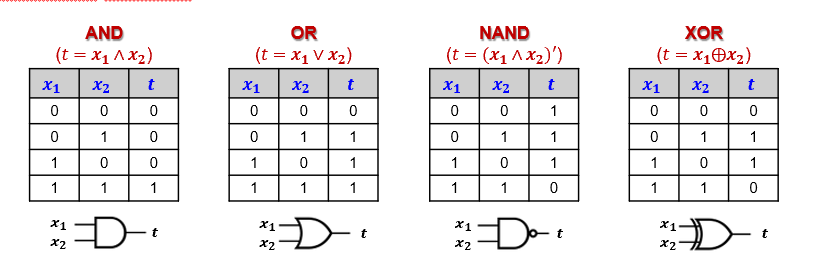
    - 논리 연산의 논리 테이블은 입력 데이터 x1, x2와 출력 t로 주어지는 학습 데이터에 의한 2-변수 logistic regression과 동일
        - 즉, 논리의 학습은 cross-entropy를 손실함수로 이용해서 logistic regression 알고리즘으로 데이터를 분류하여 결과 예측 가능
- 논리 연산 학습기와 뉴런 구조
    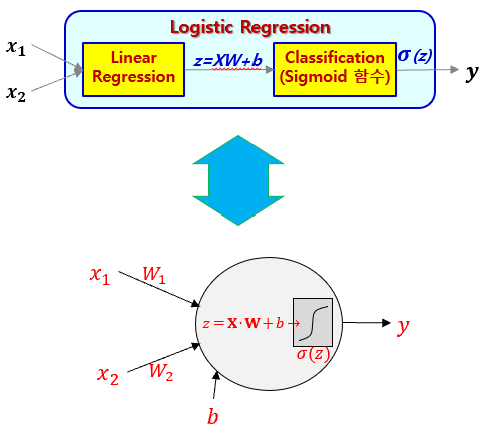
- 논리 연산 학습
    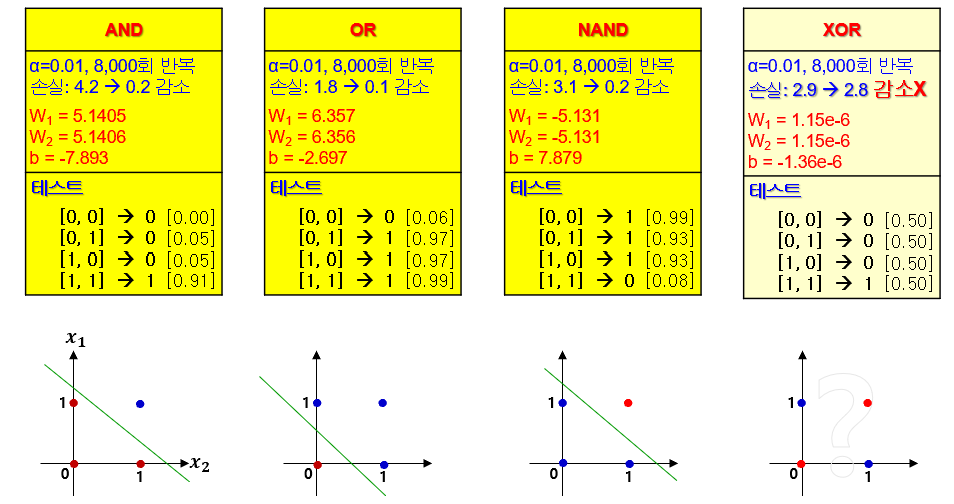
- XOR 구현
    - 단일 뉴런으로는 불가능
    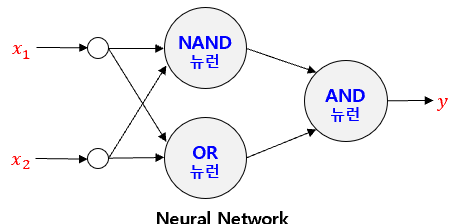
    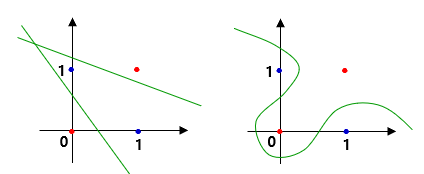
    - 뉴런 여러 개로 Multi-Layer의 망 구조로 구현 가능
        - 각각의 뉴런(nand, or, and 게이트)들은 logistic 회귀로 잘 동작
        - 입력은 화살표 방향으로 들어가며, 이전 레이어 뉴런들의 출력이 다음 레이어 뉴런의 입력으로 -> 신경망 구조를 형성 -> Neural Network
        - Multi layer NN 구성: 학습은 어떻게?
        - Backpropagation
    - 최근 딥러닝의 핵심 기술
    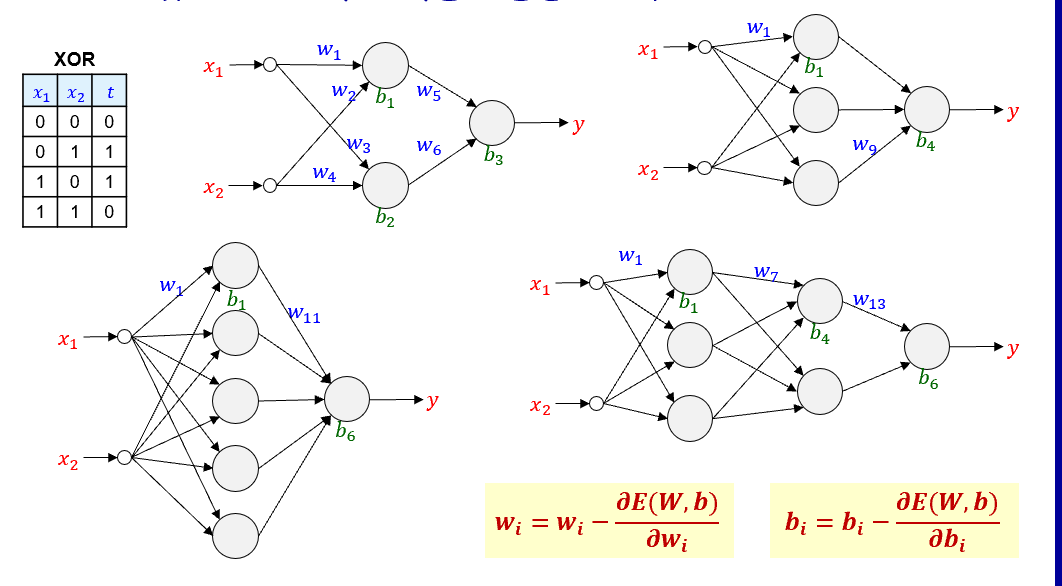
## 다층 신경망
- 입력층과 출력층 사이에 1개 이상의 Hidden layer를 가지는 신경망
    - 은닉층이 많아지면 학습의 정확도가 높아짐 -> 학습 과정이 어려워짐
    - 보통 2, 3개 이상의 은닉층을 가지면 Deep Neural Network라 함 -> Deep learning
### Error Backpropagetion
- 수치미분 보정 vs 오차 역전파 보정
    - 수치 미분
        - 수치 미분 방식은 많은 계산 시간을 요구
            - 가중치 개수만큼 입력을 신경망에 흘려보내야 함
        - 출력단의 오차만을 이용해 신경망의 모든 가중치를 출력오차 미분으로 수정함(각 노드의 기능, 역할과는 무관하게)
    - 오차 역전파
        - 출력단의 오차를 이용해 신경망을 역방향으로 전파하면서 순차적으로 오차 미분하면서 순차적으로 가중치들을 수정
        - 수학적 미분을 적용하여 공식화가 가능
        - 특히 가중치는 행렬로 표현됨으로 공식화된 행렬 알고리즘 적용 가능 (미분 계산이 없으면 빠르게 수행 가능)
        - TensorFlow는 행렬 계산이 매우 빠르므로 매우 큰 신경망도 빠르게 학습 가능함
### 신경망 예제
- 필기체 숫자 인식 (MNIST 데이터셋)
    - Modified National Institute of Standards and Technology
    - 신경망 분야의 유명한 데이터셋 - 기초부터 연구까지 다양하게 활용
    - 6만개의 학습 데이터와 1만개의 테스트 데이터
    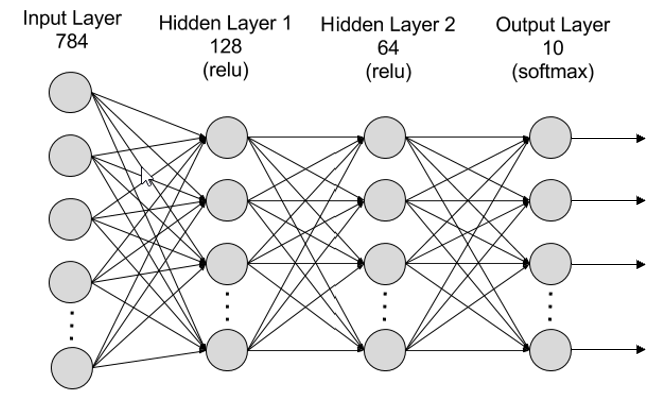
## 딥러닝
- 고려사항
    - Geoffrey Hinton's summary of findings up to today
        1. labeled datasets가 적다
        2. computer가 느리다
        3. 가중치를 멍청하게 시작함
        4. 잘못된 비선형 데이터 사용
    - 과적합 -> more dataset, drop out, regularization
    - 컴퓨터도 훨씬 빨라야 함 -> GPU, TPU 발전
    - 초기 가중치를 임의로 주면 어려움 -> RBM, Xavier/He
    - 은닉층 층수와 노드수를 신중하게 계획해야 함
    - 시그모이드 함수는 딥러닝에 맞지 않음
        - 은닉층이 많아질 시 시그모이드 함수는 Gradient vanishing
        - 대안: ReLU, Tanh, leaky ReLU, ELU ReLU, Maxout ReLU



# 행렬, 선형변환
- 입력이 가중치 행렬을 통과하는 것과 가중치 행렬이 입력을 변환하는 것은 같은 결과를 도출할 수 있음

- $X \cdot W = (W^T \cdot X^T)^T$

$$
\underbrace{
\begin{pmatrix}
  0 & 0 \\
  0 & 1 \\
  1 & 0 \\
  1 & 1
\end{pmatrix}
}_{X\;(4\times2)}
\cdot
\underbrace{
\begin{pmatrix}
  w_{11} & w_{12} & w_{13} & w_{14} & w_{15} \\
  w_{21} & w_{22} & w_{23} & w_{24} & w_{25}
\end{pmatrix}
}_{W\;(2\times5)}
=
\left(
\underbrace{
\begin{pmatrix}
  w_{11} & w_{21} \\
  w_{12} & w_{22} \\
  w_{13} & w_{23} \\
  w_{14} & w_{24} \\
  w_{15} & w_{25}
\end{pmatrix}
}_{W^T\;(5\times2)}
\cdot
\underbrace{
\begin{pmatrix}
  0 & 0 & 1 & 1 \\
  0 & 1 & 0 & 1
\end{pmatrix}
}_{X^T\;(2\times4)}
\right)^T
$$

In [1]:
import numpy as np

M = np.array([[0, 1],
              [1, 0]])
org = np.array([1, 2])

res = M @ org.T
print(res)

res = org @ M.T
print(res)

[2 1]
[2 1]


In [2]:
# 은닉층 함수 구현
from datetime import datetime

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def cross_entropy(t, y):
    delta = 1e-7
    return -np.sum(t*np.log(y+delta) + (1-t)*np.log((1-y)+delta))

def numerical_derivative(f, x):
    delta_x = 1e-4
    grad = np.zeros_like(x)
    
    it = np.nditer(x, flags=['multi_index'], op_flags=['readwrite'])
    
    while not it.finished:
        idx = it.multi_index
        tmp_val = x[idx]
        x[idx] = float(tmp_val) + delta_x
        fx1 = f(x) #(x+delta_x)
        
        x[idx] = tmp_val - delta_x
        fx2 = f(x) #(x-delta_x)
        grad[idx] = (fx1 - fx2) / (2*delta_x)
        
        x[idx] = tmp_val
        it.iternext()
    return grad

class LogicGate:
    def __init__(self, gate_name, xdata, tdata, hidden = 5):
        self.name = gate_name
        # 입력 데이터, 정답 데이터 초기화
        rows, cols = len(xdata), len(xdata[0])
        self.xdata = xdata.reshape(rows, cols) # 4개의 입력 데이터 x1, x2에 대해 batch 처리 행렬
        self.tdata = tdata.reshape(rows, 1) # 4개의 입력데이터 x1, x2에 대한 계산 값 행렬
        
        # 2층 hidden layer: 5개 가정, 가중치 W2, 편향 b2 초기화
        self.W2 = np.random.rand(cols, hidden) # 2x5
        self.b2 = np.random.rand(hidden)
        
        # 3층 output layer unit: 1개, 가중치 W3, 편향 b3 초기화
        self.W3 = np.random.rand(hidden, 1) # 5x1
        self.b3 = np.random.rand(1)
        
        # 학습률 초기화
        self.lr = 1e-2
        print(self.name + "object is created")
        
    def feed_forward(self):
        z2 = self.xdata @ self.W2 + self.b2 # 은닉층의 선형회귀
        a2 = sigmoid(z2) # 은닉층의 활성화 함수 적용
        z3 = a2 @ self.W3 + self.b3 # 출력층의 선형회귀
        y = a3 = sigmoid(z3) # 출력층의 활성화 함수 적용
        return cross_entropy(self.tdata, y) # 손실값 리턴
    
    def errValue(self): # 외부 출력을 위한 손실함수 값 계산
        return self.feed_forward()
    
    def train(self, repeat = 8000, outStep = 1000):
        f = lambda x: self.feed_forward()
        start = datetime.now()
        for step in range(repeat + 1):
            self.W2 -= self.lr * numerical_derivative(f, self.W2)
            self.b2 -= self.lr * numerical_derivative(f, self.b2)
            self.W3 -= self.lr * numerical_derivative(f, self.W3)
            self.b3 -= self.lr * numerical_derivative(f, self.b3)
            
            if step % outStep == 0:
                print("step = ", step, "error value = ", self.errValue())
        end = datetime.now()
        print("elapsed time = ", end - start)
        
    def predict(self, test):
        z2 = test @ self.W2 + self.b2 # 은닉층의 선형회귀
        a2 = sigmoid(z2) # 은닉층의 활성화 함수 적용
        z3 = a2 @ self.W3 + self.b3 # 출력층의 선형회귀
        y = a3 = sigmoid(z3) # 출력층의 활성화 함수 적용
        if y > 0.5:
            result = 1
        else:
            result = 0
        return y, result


In [3]:
# XOR gate 학습
xdata = np.array([[0, 0],
                  [0, 1],
                  [1, 0],
                  [1, 1]])
tdata = np.array([[0],
                  [1],
                  [1],
                  [0]])

XOR = LogicGate("XOR", xdata, tdata)
XOR.train(repeat = 15000)

XORobject is created
step =  0 error value =  4.628464947926172
step =  1000 error value =  2.7668194997424385
step =  2000 error value =  2.7592259701312036
step =  3000 error value =  2.742602327162402
step =  4000 error value =  2.7037550126394025
step =  5000 error value =  2.6184575593242676
step =  6000 error value =  2.4523196760056605
step =  7000 error value =  2.164488709210632
step =  8000 error value =  1.7194203422148737
step =  9000 error value =  1.191929215167706
step =  10000 error value =  0.7847470194493614
step =  11000 error value =  0.5397082522424205
step =  12000 error value =  0.3960282035999218
step =  13000 error value =  0.3069976154785319
step =  14000 error value =  0.24814790481843146
step =  15000 error value =  0.20700709005887022
elapsed time =  0:00:18.331891


In [6]:
print("===", XOR.name, "testing...")
test_data = np.array([[0, 0],
                      [0, 1],
                      [1, 0],
                      [1, 1],
                      [0.7, 0.3]])
for test in test_data:
    y = XOR.predict(test)
    print(test, " = ", y[1], " (softmax = ", y[0], ")")

=== XOR testing...
[0. 0.]  =  0  (softmax =  [0.01074896] )
[0. 1.]  =  1  (softmax =  [0.94858975] )
[1. 0.]  =  1  (softmax =  [0.94515308] )
[1. 1.]  =  0  (softmax =  [0.08333493] )
[0.7 0.3]  =  1  (softmax =  [0.5192493] )


In [7]:
# XOR 3-in gate
xdata = np.array([[0, 0, 0],
                  [0, 0, 1],
                  [0, 1, 0],
                  [0, 1, 1],
                  [1, 0, 0],
                  [1, 0, 1],
                  [1, 1, 0],
                  [1, 1, 1]])
tdata = np.array([[0],
                  [1],
                  [1],
                  [0],
                  [1],
                  [0],
                  [0],
                  [1]])

XOR3 = LogicGate("XOR3", xdata, tdata, hidden = 16)
XOR3.train(repeat = 15000)

XOR3object is created
step =  0 error value =  20.934933271746637
step =  1000 error value =  5.544553191467131
step =  2000 error value =  5.542876069505688
step =  3000 error value =  5.5411483231553
step =  4000 error value =  5.539057640087332
step =  5000 error value =  5.536174854303001
step =  6000 error value =  5.531744743535665
step =  7000 error value =  5.524263077082503
step =  8000 error value =  5.51053164791025
step =  9000 error value =  5.483334055517815
step =  10000 error value =  5.425004007700724
step =  11000 error value =  5.2943603642874795
step =  12000 error value =  5.04188737964179
step =  13000 error value =  4.692619824186531
step =  14000 error value =  4.315072161520325
step =  15000 error value =  3.9332156209752345
elapsed time =  0:00:51.251585


In [8]:
test_data = np.array([[0, 0, 0],
                      [0, 0, 1],
                      [0, 1, 0],
                      [0, 1, 1],
                      [1, 0, 0],
                      [1, 0, 1],
                      [1, 1, 0],
                      [1, 1, 1],
                      [0.7, 0.3, 0.5]])

for test in test_data:
    y = XOR3.predict(test)
    print(test, " = ", y[1], " (softmax = ", y[0], ")")

[0. 0. 0.]  =  0  (softmax =  [0.16514455] )
[0. 0. 1.]  =  1  (softmax =  [0.75945513] )
[0. 1. 0.]  =  1  (softmax =  [0.76350291] )
[0. 1. 1.]  =  0  (softmax =  [0.42877395] )
[1. 0. 0.]  =  1  (softmax =  [0.7602607] )
[1. 0. 1.]  =  0  (softmax =  [0.42558335] )
[1. 1. 0.]  =  0  (softmax =  [0.42661931] )
[1. 1. 1.]  =  0  (softmax =  [0.2827879] )
[0.7 0.3 0.5]  =  1  (softmax =  [0.58998308] )


# Scikit-learn
## 개요
- Numpy와 Scipy 위에서 구축된 라이브러리
    - 구글 summer project, SciKit(Scipy toolkit)에서 시작
    - 오랜 기간 사용되어 성숙한 라이브러리
    - 파이썬 설치 시 기본적으로 설치됨
- 데이터 마이닝과 머신러닝을 위한 하이레벨 라이브러리
    - 지도학습, 비지도학습에 관련된 다양한 메서드를 제공하기 때문에 간단하게 학습 알고리즘을 사용하려 할 때 효율적
    - 주로 Decision tree, Regression, svm, k-NN, ensenble, PCA와 같은 머신러닝 메서드 제공
    - 딥러닝이나 강화학습은 다루지 않음
    - 텐서플로우는 상대적으로 로우레벨 라이브러리에 가까움
        - 텐서플로우는 신경망이나 딥러닝 위주의 데이터 계산, 연산을 위한 라이브러리
        - 2020년 Keras 통합으로 하이레벨 플랫폼으로 변화
## 특징
- 다양한 머신러닝용 라이브러리 제공
- 심플하고 일관성 있는 api, 유용한 온라인 문서, 풍부한 예제
- 머신러닝을 위한 쉽고 효율적인 개발 라이브러리 제공
- 많은 사람들이 사용하며 다양한 환경에서 검증된 라이브러리
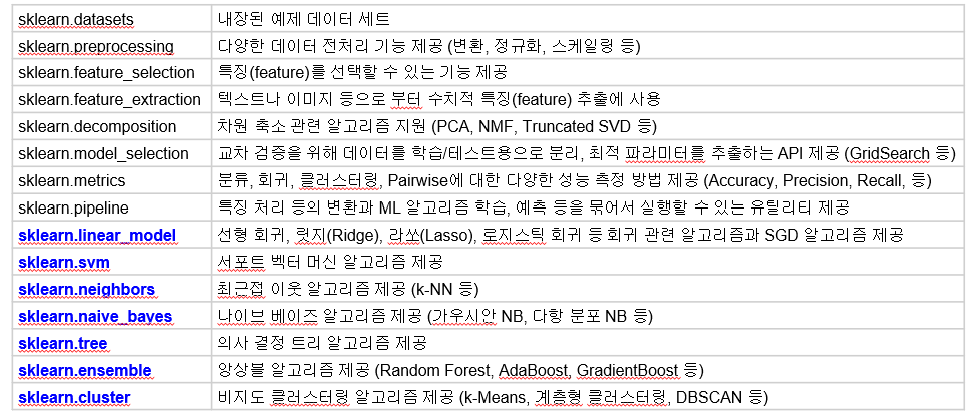

## Estimator API 사용
- 적절한 estimator 클래스를 임포트해서 모델의 클래스 선택
- 클래스를 원하는 값으로 인스턴스화해서 모델의 하이퍼 파라미터 선택
- 데이터를 특징 배열과 타겟 벡터로 배치
- 모델 인스턴스의 fit() 메서드로 데이터 학습
- 모델을 새 데이터에 대해 적용
    - 지도학습: 대체로 predict() 메서드로 예측
    - 비지도학습: transform이나 predict 메서드로 데이터의 속성을 변환하거나 추론
    

In [1]:
# 선형회귀 Scikit-learn
import numpy as np
import matplotlib.pyplot as plt
from sklearn import set_config
from sklearn.linear_model import LinearRegression

# Avoid HTML rendering that reads bundled JavaScript with the Windows encoding.
set_config(display="text")

lrModel = LinearRegression(fit_intercept=True)
print(lrModel)

LinearRegression()


In [14]:
x = np.array([9, 14, 21, 27, 32, 37])
x = x.reshape(-1, 1) # 2차원 배열로 변환
y = np.array([74, 81, 86, 90, 88, 92])
lrModel.fit(x, y) # 선형회귀 모델 학습

LinearRegression()

In [ ]:
tx = np.array([24, 34, 11, 42])
tx = tx.reshape(-1, 1) # 2차원 배열로 변환
predicted = lrModel.predict(tx)
print("predicted = ", predicted)

predicted =  [85.55348837 91.35581395 78.01046512 95.99767442]


In [17]:
print(lrModel.coef_) # 기울기
print(lrModel.intercept_) # 절편

[0.58023256]
71.62790697674419


테스트 데이터 [ 5 10 15 20 25 30 35 40]
예측 데이터 [74.52906977 77.43023256 80.33139535 83.23255814 86.13372093 89.03488372
 91.93604651 94.8372093 ]


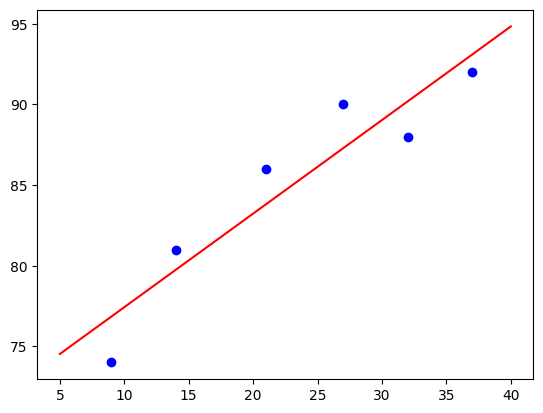

In [18]:
nx = np.arange(5, 45, 5)
nX = nx.reshape(-1, 1) # 2차원 배열로 변환
ny = lrModel.predict(nX)

print("테스트 데이터", nx)
print("예측 데이터", ny)

plt.scatter(x, y, color='blue', label='data')
plt.plot(nX, ny, color='red', label='prediction')


In [2]:
# logistic regression

import numpy as np
from sklearn.linear_model import LogisticRegression

logiMd = LogisticRegression()

x_data = np.array([ [2, 4],
                   [4, 11],
                   [6, 6],
                   [8, 5],
                   [10, 7],
                   [12, 16],
                   [14, 8],
                   [16, 3],
                   [18, 7]])

t_data = np.array([0,0,0,0,1,1,1,1,1])

logiMd.fit(x_data, t_data)
print(logiMd)

LogisticRegression()


In [3]:
print(logiMd.get_params())

{'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 0.0, 'max_iter': 100, 'n_jobs': None, 'penalty': 'deprecated', 'random_state': None, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}


In [4]:
print("학습 데이터 점수: {}".format(logiMd.score(x_data, t_data)))

학습 데이터 점수: 1.0


In [5]:
test_data = np.array([[3, 17],
                      [5, 8],
                      [7, 5],
                      [9, 6],
                      [11, 9],
                      [13, 15],
                      [15, 4],
                      [17, 8],
                      [19, 2]])
logiMd.predict(test_data)


array([0, 0, 0, 0, 1, 1, 1, 1, 1])

In [6]:
print(logiMd.coef_) # 기울기
print(logiMd.intercept_) # 절편

[[0.9046569  0.30593173]]
[-10.1870571]


# Scikit-Learn Datasets
- 빌트인 데이터셋 제공
- 데이터셋 조회
    - key:value 딕셔너리 형태
    - 공통 key
        - data
        - target
        - feature_names
        - target_names
        DESCR
        - filename

In [2]:
import pandas as pd
from sklearn.datasets import load_iris

iris = load_iris()
print(iris.keys())
print(iris['target_names'])
print(iris['feature_names'])
print(iris['filename'])
print(iris['DESCR'])

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])
['setosa' 'versicolor' 'virginica']
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
iris.csv
.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9  

In [5]:
iris_df = pd.DataFrame(data = iris.data, columns = iris.feature_names)

iris_df['Target'] = iris.target

iris_df.info
iris_df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


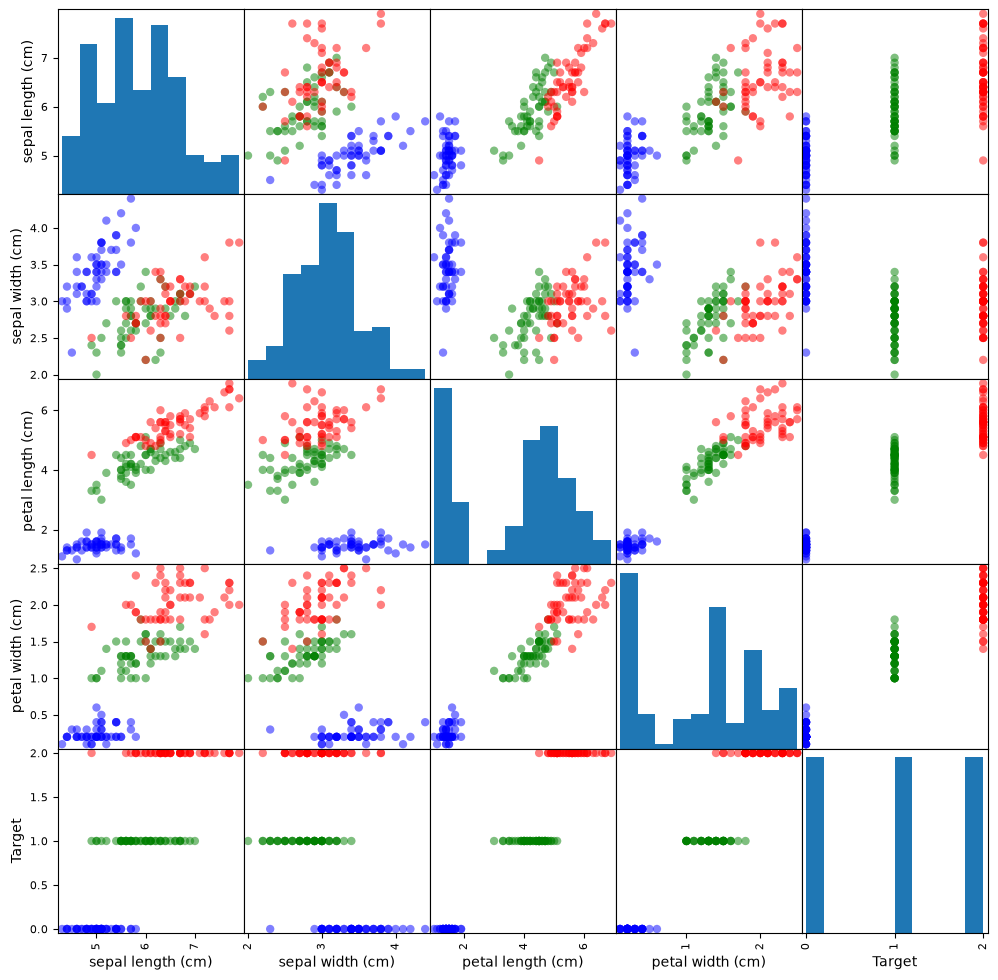

In [7]:
col_dict = {0: 'blue', 1:'green', 2:'red'}
cols = [col_dict[x] for x in iris_df['Target']]
pd.plotting.scatter_matrix(iris_df, color = cols, figsize = (12, 12), marker = 'o') ;


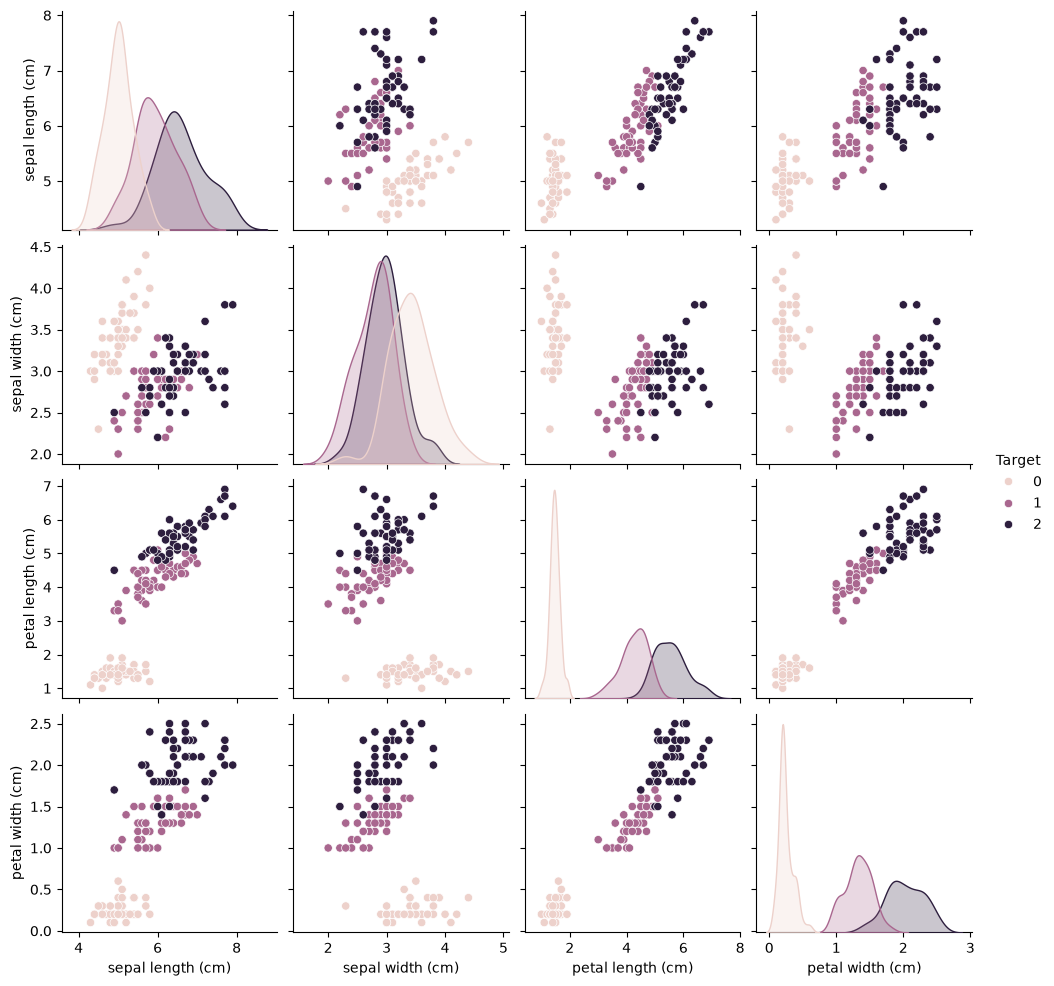

In [8]:
import seaborn as sns
sns.pairplot(hue = 'Target', data = iris_df)

# k-NN
## k-Nearest Neighborhoodw
- 입력 데이터 포인트와 가장 가까운 k개의 훈련 데이터 포인트를 선택
- k개의 데이터로 분류


In [12]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

X, y = load_iris(return_X_y = True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 11)

md = KNeighborsClassifier(n_neighbors = 5)
md.fit(X_train, y_train)
print(md.get_params())

{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'minkowski', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}


In [13]:
test_ex = np.array([[6, 3, 5, 1.6]])
pred = md.predict(test_ex)
iris = load_iris()
print(pred, iris['target_names'][pred])
print('KNN 테스트 데이터의 score: {}'.format(md.score(X_test, y_test)))


[2] ['virginica']
KNN 테스트 데이터의 score: 0.9666666666666667


# 모델 학습 시 같이 활용하면 좋은 도구들
- 데이터 정규화
    - 표준 정규 분포로 표준화
    - 0 ~ 1 사이로 정규화
- Cross Validation
    - 학습데이터의 일부를 이용해 학습과 테스트 반복
- 최적 파라미터 찾기
    - 학습 모델의 다양한 파라미터들의 최적값을 찾는 도구
- 2차원 분류 이미지
    - 고차원 데이터를 2차원으로 축소(t-SNE, PCA, UMAP)
    - 분류 이미지 생성

# SVM
## Support Vector Machine
- 딥러닝 이전에 좋은 성능으로 주목받은 분류 모델
- 분류를 위해 가장 좋은 결정 경계를 학습하는 기법
    - 결정 경계: 데이터를 가장 잘 분리하는 경계
    - 서포트 벡터: 결정 경계와 가장 가까운 점들
    - 마진: 결정 경계와 서포트 벡터의 거리 * 2
    - SVM은 이러한 마진을 최대화하는 분류모델


In [15]:
from sklearn.svm import SVC
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler

X, y = load_iris(return_X_y = True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 11)

svcMd = SVC(kernel = 'linear')
svcMd.fit(X_train, y_train)

SVC(kernel='linear')

In [16]:
print("SVC 학습 데이터 점수: {:.3f}".format(svcMd.score(X_train, y_train)))
print("SVC 테스트 데이터 점수: {:.3f}".format(svcMd.score(X_test, y_test)))

SVC 학습 데이터 점수: 0.983
SVC 테스트 데이터 점수: 1.000


In [17]:
scaler = StandardScaler()
scaler.fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

In [21]:
scaledSvcMd = SVC(kernel = 'linear')
scaledSvcMd.fit(X_train, y_train)
print("SVC 학습 데이터 점수: {:.3f}".format(scaledSvcMd.score(X_train, y_train)))
print("SVC 테스트 데이터 점수: {:.3f}".format(scaledSvcMd.score(X_test, y_test)))

SVC 학습 데이터 점수: 0.983
SVC 테스트 데이터 점수: 0.967


In [22]:
scaledSvcMd = SVC(kernel = 'rbf', C = 10, gamma = 0.1)
scaledSvcMd.fit(X_train, y_train)
print("SVC 학습 데이터 점수: {:.3f}".format(scaledSvcMd.score(X_train, y_train)))
print("SVC 테스트 데이터 점수: {:.3f}".format(scaledSvcMd.score(X_test, y_test)))

SVC 학습 데이터 점수: 0.975
SVC 테스트 데이터 점수: 0.933


In [23]:
scaledSvcMd = SVC(kernel = 'rbf', C = 1, gamma = 0.1)
scaledSvcMd.fit(X_train, y_train)
print("SVC 학습 데이터 점수: {:.3f}".format(scaledSvcMd.score(X_train, y_train)))
print("SVC 테스트 데이터 점수: {:.3f}".format(scaledSvcMd.score(X_test, y_test)))

SVC 학습 데이터 점수: 0.967
SVC 테스트 데이터 점수: 0.933


In [25]:
scaledSvcMd = SVC(kernel = 'poly', degree = 10, coef0 = 1, C = 1)
scaledSvcMd.fit(X_train, y_train)
print("SVC 학습 데이터 점수: {:.3f}".format(scaledSvcMd.score(X_train, y_train)))
print("SVC 테스트 데이터 점수: {:.3f}".format(scaledSvcMd.score(X_test, y_test)))

SVC 학습 데이터 점수: 1.000
SVC 테스트 데이터 점수: 0.900


## C 파라미터: 오류 허용 정도 조정
- 규제(L2 regularization) 정도로 과적합을 조절
- C가 커짐
    - 규제가 커지며 과대적합
    - 오류를 최대한 줄이려 함
    - 마진폭이 좁아짐 (hard margin)

- C가 작아짐
    - 규제가 줄어줄며 과소적합
    - 오류를 허용
    - 마진폭이 넓어짐 (soft margin)
- C의 최적값은 데이터에 따라 다름. 결국 여러가지 C값을 대입해보며 검증

## 커널
- Linear, Polynomial, RBF(Radial Basis Function) 등 다양함
- 커널에 따라 다양한 매개변수 설정 가능
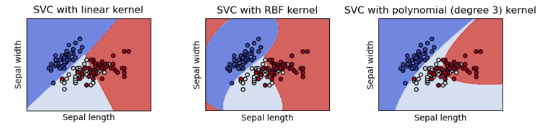
- rbf
    - 방사기저함수(가우시안 커널)로 차원을 높혀 분류
    - gamma가 커지면 경계가 많이 휘어짐
- poly
    - 다항식 커널로 주어진 특성에 다항식 특성 추가
    - coef0: 계수의 영향력

# Decision Tree
- 의사결정 규칙을 트리로 나타내어 전체 데이터를 소집단으로 분류
- 트리 분기 기준
    - 전체 데이터를 잘 분리(순도 높게) 할 수 있는 특징(속성)들을 차례대로 찾아서 데이터를 분할하면서 전체 트리 구성
    - 불순도를 속성들에 대해 반복적으로 계산
        - 지니 계수: 확률적 분산 정도(Cart 알고리즘)
        - 엔트로피 계수: 불확실성 정도

In [27]:
%pip install graphviz -q

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import graphviz
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import cross_validate

iris = load_iris()
dtMd = DecisionTreeClassifier()
dtMd.fit(iris.data, iris.target)




DecisionTreeClassifier()

In [3]:
test_ex = np.array([[6, 3, 5, 1.6]])
pred = dtMd.predict(test_ex)
print(pred, iris.target_names[pred[0]])

[1] versicolor


|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.75
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- petal width (cm) <= 1.65
|   |   |   |   |--- class: 1
|   |   |   |--- petal width (cm) >  1.65
|   |   |   |   |--- class: 2
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- petal width (cm) <= 1.55
|   |   |   |   |--- class: 2
|   |   |   |--- petal width (cm) >  1.55
|   |   |   |   |--- sepal length (cm) <= 6.95
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- sepal length (cm) >  6.95
|   |   |   |   |   |--- class: 2
|   |--- petal width (cm) >  1.75
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- sepal width (cm) <= 3.10
|   |   |   |   |--- class: 2
|   |   |   |--- sepal width (cm) >  3.10
|   |   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- class: 2



[Text(0.5, 0.9166666666666666, 'petal length (cm) <= 2.45\ngini = 0.667\nsamples = 150\nvalue = [50, 50, 50]\nclass = setosa'),
 Text(0.4230769230769231, 0.75, 'gini = 0.0\nsamples = 50\nvalue = [50, 0, 0]\nclass = setosa'),
 Text(0.46153846153846156, 0.8333333333333333, 'True  '),
 Text(0.5769230769230769, 0.75, 'petal width (cm) <= 1.75\ngini = 0.5\nsamples = 100\nvalue = [0, 50, 50]\nclass = versicolor'),
 Text(0.5384615384615384, 0.8333333333333333, '  False'),
 Text(0.3076923076923077, 0.5833333333333334, 'petal length (cm) <= 4.95\ngini = 0.168\nsamples = 54\nvalue = [0, 49, 5]\nclass = versicolor'),
 Text(0.15384615384615385, 0.4166666666666667, 'petal width (cm) <= 1.65\ngini = 0.041\nsamples = 48\nvalue = [0, 47, 1]\nclass = versicolor'),
 Text(0.07692307692307693, 0.25, 'gini = 0.0\nsamples = 47\nvalue = [0, 47, 0]\nclass = versicolor'),
 Text(0.23076923076923078, 0.25, 'gini = 0.0\nsamples = 1\nvalue = [0, 0, 1]\nclass = virginica'),
 Text(0.46153846153846156, 0.416666666666

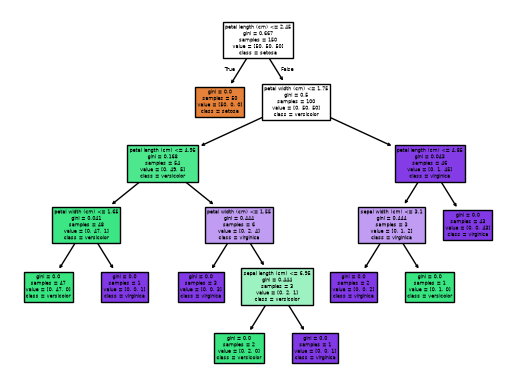

In [6]:
dt = tree.export_text(decision_tree = dtMd, feature_names = iris.feature_names)

print(dt)
tree.plot_tree(dtMd, feature_names = iris.feature_names, class_names = iris.target_names, filled = True)

In [12]:
gdt = tree.export_graphviz(decision_tree = dtMd,
                           feature_names = iris.feature_names,
                           class_names = iris.target_names,
                           filled = True,
                           rounded = True,
                           special_characters = True)

graph = graphviz.Source(gdt)
print(graph)


digraph Tree {
node [shape=box, style="filled, rounded", color="black", fontname="helvetica"] ;
edge [fontname="helvetica"] ;
0 [label=<petal length (cm) &le; 2.45<br/>gini = 0.667<br/>samples = 150<br/>value = [50, 50, 50]<br/>class = setosa>, fillcolor="#ffffff"] ;
1 [label=<gini = 0.0<br/>samples = 50<br/>value = [50, 0, 0]<br/>class = setosa>, fillcolor="#e58139"] ;
0 -> 1 [labeldistance=2.5, labelangle=45, headlabel="True"] ;
2 [label=<petal width (cm) &le; 1.75<br/>gini = 0.5<br/>samples = 100<br/>value = [0, 50, 50]<br/>class = versicolor>, fillcolor="#ffffff"] ;
0 -> 2 [labeldistance=2.5, labelangle=-45, headlabel="False"] ;
3 [label=<petal length (cm) &le; 4.95<br/>gini = 0.168<br/>samples = 54<br/>value = [0, 49, 5]<br/>class = versicolor>, fillcolor="#4de88e"] ;
2 -> 3 ;
4 [label=<petal width (cm) &le; 1.65<br/>gini = 0.041<br/>samples = 48<br/>value = [0, 47, 1]<br/>class = versicolor>, fillcolor="#3de684"] ;
3 -> 4 ;
5 [label=<gini = 0.0<br/>samples = 47<br/>value = [0, 47

# Naive Bayes 분류
- Bayes 정리를 적용한 확률적 분류 알고리즘
- 일반적으로 H 사건의 확률을 알아보는 데 있어서
    - P(H)만으로 확률 계산: 단순 빈도수에 의한 확률
        - Prior 확률: 아무런 근거(증거, 증상) 없이 H가 일어날 통계적 확률
        - 사전 지식, 배경 지식이라고 함
    - P(H|E): 어떤 evidence/실마리/특징 있는 사건 발행 이후에 H가 발생할 것으로 믿을 수 있는 확률
    - Bayesian 조건 확률 정리
        - 사후 확률: 추가 정보로 인해서 H 사건에 대한 믿음에 변화가 일어남
$$P(E|H) = \frac{P(EH)P(H)}{P(E)}$$
- P(E|H): likelyhood: 어떤 사건이 어떤 특징/징후를 가질 확률
- P(E): 전체 사건에서 E의 특징을 가지는 사건의 확률\

## 예시
- 100명의 대학생 (남:여 = 반반)
- 임의의 한 학생에 대해 어느 쪽으로 부ㅠㄴ류할까
    - P(남) = 0.5, P(여) = 0.5
    - 사전 지식 없이는 반반
- 만약 어떤 특징 값이 주어진다면?
    - 키, 몸무게 등
    - 키가 175라는 정보가 있다면?
    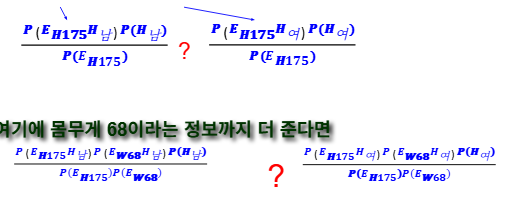

## Naive Bayes(일반화)
- n개 클래스(C1, C2, C3, ...), m개의 특징 벡터
$$p(c_kx_1, ..., x_m) = \frac{p(x_1c_k)p(x_2c_k)...p(x_mc_k)p(c_k)}{p(X)}$$
는 서로 독립임을 가정함 -> Naive한 가정

$$\text{max}_kp(c_k)\prod^m_{i=1}p(x_ic_k)$$

In [14]:
import numpy as np
import pandas as pd
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.datasets import load_iris, fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn import metrics

prior = [0.45, 0.3, 0.15, 0.1] # 4개 클래스가 있고 각 클래스는 특징을 가짐
likelihood = [[0.3, 0.3, 0.4],
              [0.2, 0.5, 0.3],
              [0.1, 0.4, 0.5],
              [0.6, 0.2, 0.2]] # 클래스를 위한 특징별 기능도

for i, c in enumerate(prior):
    result = 1
    for x in likelihood[i]:
        result *= x
    result *= c
    print(f"Class {i} likelihood: {result:.5f}")

Class 0 likelihood: 0.01620
Class 1 likelihood: 0.00900
Class 2 likelihood: 0.00300
Class 3 likelihood: 0.00240


In [16]:
iris = load_iris()
gNB_Md = GaussianNB()
gNB_Md.fit(iris.data, iris.target)


GaussianNB()

In [18]:
test_ex = np.array([[6, 3, 5, 1.6]])
pred = gNB_Md.predict(test_ex)
print(pred, iris['target_names'][pred[0]])

[1] versicolor


In [20]:
gNB_Md.predict(iris.data[[10, 20, 55, 77, 120, 135]])

array([0, 0, 1, 2, 2, 2])

In [21]:
print(gNB_Md.predict_proba(iris.data)[[10, 20, 55, 77, 120, 135]].round(2))

[[1.   0.   0.  ]
 [1.   0.   0.  ]
 [0.   1.   0.  ]
 [0.   0.08 0.92]
 [0.   0.   1.  ]
 [0.   0.   1.  ]]


In [22]:
pred = gNB_Md.predict(iris.data)
metrics.confusion_matrix(iris.target, pred)

array([[50,  0,  0],
       [ 0, 47,  3],
       [ 0,  3, 47]])

In [23]:
md_prior = GaussianNB(priors = [0.1, 0.1, 0.8])
md_prior.fit(iris.data, iris.target)
pred_prior = md_prior.predict(iris.data)
metrics.confusion_matrix(iris.target, pred_prior)

array([[50,  0,  0],
       [ 0, 42,  8],
       [ 0,  2, 48]])

In [24]:
md_prior = GaussianNB(priors = [0.1, 0.8, 0.1])
md_prior.fit(iris.data, iris.target)
pred_prior = md_prior.predict(iris.data)
metrics.confusion_matrix(iris.target, pred_prior)

array([[50,  0,  0],
       [ 0, 49,  1],
       [ 0,  7, 43]])

## 문서데이터
- Bag of Word(TF, TF-IDF)
- 문서 분류에 사용, 스팸 메일, 문서 종류, 특성 등
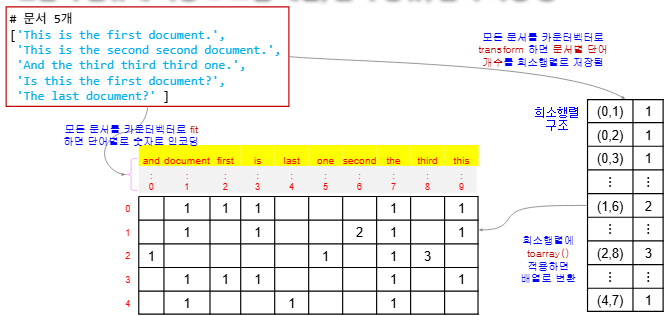
- TF - IDF (Term Frequency - Inverse Documnet Frequency)
    - 특정 문서에서 특정 단어의 중요도(그 단어를 포함하는 문서가 많으면 작아짐, 단어의 특수성)
    - 특정 단어에 대해, 단어 빈도수를 그 단어를 포함하는 문서의 비율의 역수를 곱
    - 어떤 단어가 특정 문서에 특히 많은 경우를 판단 가능
$$TF(전체문서수/포함문서수)$$

In [25]:
ng = fetch_20newsgroups()


In [26]:
ng.data
ng.target_names

['alt.atheism',
 'comp.graphics',
 'comp.os.ms-windows.misc',
 'comp.sys.ibm.pc.hardware',
 'comp.sys.mac.hardware',
 'comp.windows.x',
 'misc.forsale',
 'rec.autos',
 'rec.motorcycles',
 'rec.sport.baseball',
 'rec.sport.hockey',
 'sci.crypt',
 'sci.electronics',
 'sci.med',
 'sci.space',
 'soc.religion.christian',
 'talk.politics.guns',
 'talk.politics.mideast',
 'talk.politics.misc',
 'talk.religion.misc']

In [28]:
X_train, X_test, y_train, y_test = train_test_split(ng.data, ng.target, test_size = 0.2, random_state = 11)

In [29]:
tfidf = TfidfVectorizer()
X_train_td = tfidf.fit_transform(X_train)
X_test_td = tfidf.transform(X_test)

In [31]:
mNB = MultinomialNB()
mNB.fit(X_train_td, y_train)

MultinomialNB()

In [32]:
pred = mNB.predict(X_train_td)
aoc = metrics.accuracy_score(y_train, pred)
f1 = metrics.f1_score(y_train, pred, average = None)

print('학습 정확도: {:.3f}'.format(aoc))
print('학습 F1 점수: {}'.format(f1))

학습 정확도: 0.934
학습 F1 점수: [0.89494163 0.9625     0.95768374 0.93819656 0.98146129 0.97155361
 0.91415831 0.96815287 0.98880977 0.98852972 0.98274112 0.94152626
 0.95869565 0.98170075 0.98497854 0.77587612 0.92713833 0.97627119
 0.86206897 0.47263682]


In [33]:
pred = mNB.predict(X_test_td)
aoc = metrics.accuracy_score(y_test, pred)
f1 = metrics.f1_score(y_test, pred, average = None)

print('테스트 정확도: {:.3f}'.format(aoc))
print('테스트 F1 점수: {}'.format(f1))

테스트 정확도: 0.849
테스트 F1 점수: [0.76190476 0.75897436 0.86419753 0.78431373 0.89497717 0.91129032
 0.79591837 0.9140625  0.93518519 0.9527897  0.94166667 0.84363636
 0.84018265 0.94514768 0.92193309 0.7        0.81818182 0.96414343
 0.73619632 0.29268293]


# Ensemble
- 여러 학습 모델을 혼합하여 학습하는 방식
    - Voting, Bagging, Boosting 등
## Voting
- 다른 종류의 모델을 여러 개 사용 (같은 데이터셋으로 학슴)
- 각 모델의 결과를 수합하여 최종 결과를 도출
    - Hard voting: 각 모델의 결과 수를 종합하여 최종 결과 결정
    - Soft voting: 각 모델의 결과 확률를 종합하여 최종 결과 결정
    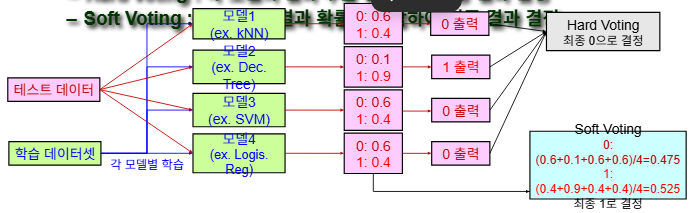

In [34]:
import numpy as np
from sklearn.ensemble import VotingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

X, y = load_iris(return_X_y = True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 11)


In [35]:
# Hard voting
voteClf = VotingClassifier(
    estimators = [('lgr', LogisticRegression()),
                  ('knn', KNeighborsClassifier(n_neighbors = 5)),
                  ('svc', SVC(kernel = 'linear', probability = True)),
                  ('dt', DecisionTreeClassifier())]
)

In [36]:
voteClf.fit(X_train, y_train)
print("hard voting 학습 평가", voteClf.score(X_train, y_train))
print("hard voting 테스트 평가", voteClf.score(X_test, y_test))

hard voting 학습 평가 0.975
hard voting 테스트 평가 0.9333333333333333


c:\Users\vbnm9\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [37]:
for name, clf in voteClf.named_estimators_.items():
    print(name, "학습 평가", clf.score(X_train, y_train))
    print(name, "테스트 평가", clf.score(X_test, y_test))

lgr 학습 평가 0.9666666666666667
lgr 테스트 평가 0.9333333333333333
knn 학습 평가 0.9666666666666667
knn 테스트 평가 0.9666666666666667
svc 학습 평가 0.9833333333333333
svc 테스트 평가 1.0
dt 학습 평가 1.0
dt 테스트 평가 0.9333333333333333


In [38]:
print('개표 결과', list(voteClf.predict(X_test[:10])))
list(clf.predict(X_test[:10]) for name, clf in voteClf.named_estimators_.items())

개표 결과 [np.int64(2), np.int64(2), np.int64(1), np.int64(1), np.int64(2), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(1)]


[array([2, 2, 1, 1, 2, 0, 1, 0, 0, 1]),
 array([2, 2, 2, 1, 2, 0, 1, 0, 0, 1]),
 array([2, 2, 2, 1, 2, 0, 1, 0, 0, 1]),
 array([2, 2, 1, 1, 2, 0, 1, 0, 0, 1])]

In [39]:
# Soft voting
voteClf.voting = 'soft'
voteClf.named_estimators_['svc'].probability = True
voteClf.fit(X_train, y_train)
print("soft voting 학습 평가", voteClf.score(X_train, y_train))
print("soft voting 테스트 평가", voteClf.score(X_test, y_test))

soft voting 학습 평가 1.0
soft voting 테스트 평가 0.9333333333333333


c:\Users\vbnm9\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


## Bagging
- Bootstrap & Aggregating
- 학습 데이터를 샘플링하여 (중복 가능/불가) 여러 개의 학습 데이터셋을 구축하고, 각각을 동일한 학습 모델에 학습시켜 결과를 종합하여 최종 결정
- 랜덤 포레스트 등

In [41]:
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.svm import SVC
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

X, y = load_iris(return_X_y = True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 11)

rfc = RandomForestClassifier(n_estimators = 100, max_depth = 3, random_state = 11)
rfc.fit(X_train, y_train)
print("Random Forest 학습 평가", rfc.score(X_train, y_train))
print("Random Forest 테스트 평가", rfc.score(X_test, y_test))

Random Forest 학습 평가 0.975
Random Forest 테스트 평가 0.9333333333333333


In [42]:
# Bagging
bagging = BaggingClassifier(estimator = SVC(),
                            n_estimators = 10,
                            random_state = 11)

bagging.fit(X_train, y_train)
print("Bagging 학습 평가", bagging.score(X_train, y_train))
print("Bagging 테스트 평가", bagging.score(X_test, y_test))

Bagging 학습 평가 0.9583333333333334
Bagging 테스트 평가 0.9333333333333333


## Boosting
- 약한 학습기를 순차적으로 학습하되, 이전 학습에 대한 잘못 예측된 데이터에 가중치를 부여해 오차를 보완해나가는 방식 - 병렬 처리 불가
- 대표적인 방식으로 AdaBoost, GDBoost가 있음

# 실습

In [2]:
lrModel.get_params()

{'copy_X': True,
 'fit_intercept': True,
 'n_jobs': None,
 'positive': False,
 'tol': 1e-06}

In [3]:
x = np.array([9, 14, 21, 27, 32, 37]).reshape(-1, 1) # 2차원 배열로 변환
y = np.array([74, 81, 86, 90, 88, 92])

lrModel.fit(x, y)

LinearRegression()

In [5]:
tx = np.array([24, 34, 11, 42]).reshape(-1, 1) # 2차원 배열로 변환
predict = lrModel.predict(tx)

In [7]:
print("predicted = ", predict)

predicted =  [85.55348837 91.35581395 78.01046512 95.99767442]


In [9]:
print(lrModel.coef_, lrModel.intercept_)

[0.58023256] 71.62790697674419


테스트 데이터 [ 5 10 15 20 25 30 35 40]
예측 결과 [74.52906977 77.43023256 80.33139535 83.23255814 86.13372093 89.03488372
 91.93604651 94.8372093 ]


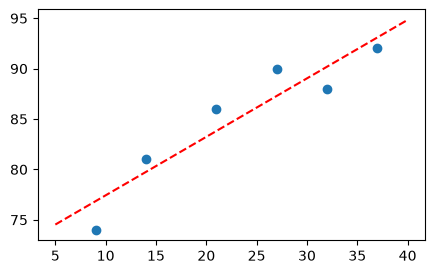

In [10]:
nx = np.arange(5, 45, 5)
nX = nx.reshape(-1, 1)
ny = lrModel.predict(nX)
print("테스트 데이터", nx)
print("예측 결과", ny)

plt.figure(figsize = (5, 3))
plt.scatter(x, y)
plt.plot(nX, ny, 'r--')

In [12]:
raw_data = np.array(
            [[73, 80, 75, 152],
             [93, 88, 93, 185],
             [89, 91, 90, 180],
             [96, 98, 100, 196],
             [73, 66, 70, 142],
             [53, 46, 55, 101],
             [69, 74, 77, 149],
             [47, 56, 60, 115],
             [87, 79, 90, 175],
             [79, 70, 88, 164],
             [69, 70, 73, 141],
             [70, 65, 74, 141],
             [93, 95, 91, 184],
             [79, 80, 73, 152],
             [70, 73, 78, 148],
             [93, 89, 96, 192],
             [78, 75, 68, 147],
             [81, 90, 93, 183],
             [88, 92, 86, 177],
             [78, 83, 77, 159],
             [82, 86, 90, 177],
             [86, 82, 89, 175],
             [78, 83, 85, 175],
             [76, 83, 71, 149],
             [96, 93, 95, 192]], dtype='f')

x_data = raw_data[:, 0:-1]
t_data = raw_data[:, -1]

print(x_data.ndim, x_data.shape)
print(t_data.ndim, t_data.shape)

2 (25, 3)
1 (25,)


In [13]:
lr3 = LinearRegression()
lr3.fit(x_data, t_data)

print("학습 데이터 점수: {}".format(lr3.score(x_data, t_data)))

학습 데이터 점수: 0.9896615743637085


In [15]:
test_data = np.array([[73, 80, 75],
                      [93, 88, 93],
])
pred = lr3.predict(test_data)
print(pred)
print(lr3.coef_, lr3.intercept_)

[152.60718581 185.08010468]
[0.35593864 0.54251873 1.1674442 ] -4.336151


In [17]:
import pandas as pd
df = pd.DataFrame(data = x_data, columns = ['국어', '영어', '수학'], index = range(1, 26))
df['모의고사'] = t_data
df

,국어,영어,수학,모의고사
1,73.0,80.0,75.0,152.0
2,93.0,88.0,93.0,185.0
3,89.0,91.0,90.0,180.0
4,96.0,98.0,100.0,196.0
5,73.0,66.0,70.0,142.0
6,53.0,46.0,55.0,101.0
7,69.0,74.0,77.0,149.0
8,47.0,56.0,60.0,115.0
9,87.0,79.0,90.0,175.0
10,79.0,70.0,88.0,164.0


In [18]:
df.describe

<bound method NDFrame.describe of       국어    영어     수학   모의고사
1   73.0  80.0   75.0  152.0
2   93.0  88.0   93.0  185.0
3   89.0  91.0   90.0  180.0
4   96.0  98.0  100.0  196.0
5   73.0  66.0   70.0  142.0
6   53.0  46.0   55.0  101.0
7   69.0  74.0   77.0  149.0
8   47.0  56.0   60.0  115.0
9   87.0  79.0   90.0  175.0
10  79.0  70.0   88.0  164.0
11  69.0  70.0   73.0  141.0
12  70.0  65.0   74.0  141.0
13  93.0  95.0   91.0  184.0
14  79.0  80.0   73.0  152.0
15  70.0  73.0   78.0  148.0
16  93.0  89.0   96.0  192.0
17  78.0  75.0   68.0  147.0
18  81.0  90.0   93.0  183.0
19  88.0  92.0   86.0  177.0
20  78.0  83.0   77.0  159.0
21  82.0  86.0   90.0  177.0
22  86.0  82.0   89.0  175.0
23  78.0  83.0   85.0  175.0
24  76.0  83.0   71.0  149.0
25  96.0  93.0   95.0  192.0>

In [19]:
# Polynomial Regression

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
import numpy as np
import matplotlib.pyplot as plt


		X				y
[[-0.59990558  2.8786749 ]
 [-1.72637017  2.93325901]
 [ 0.32940774  2.43952296]
 [-1.8340034   2.64101831]
 [ 0.18964482  3.89047496]
 [ 2.76597153  9.54735141]
 [-0.51044403  2.39293116]
 [ 1.6029346   6.25364304]
 [-1.96862391  3.04510216]
 [ 2.78808567  9.16879987]]


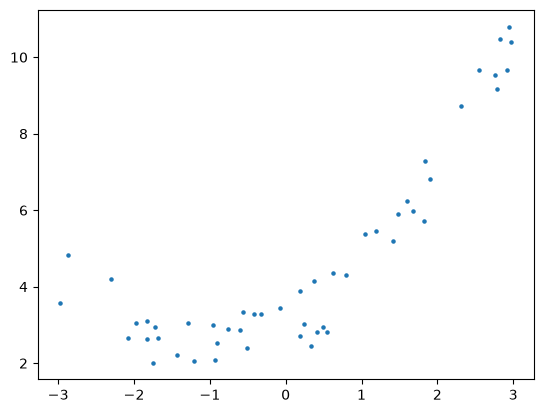

In [21]:
n = 50
X = 6 * np.random.rand(n, 1) - 3
y = 0.5 * X**2 + X + 2 + np.random.rand(n, 1)*2
print("\t\tX\t\t\t\ty"); print(np.hstack([X, y])[:10, :])

plt.scatter(X, y, s = 5)

In [22]:
poly_features = PolynomialFeatures(degree = 2, include_bias = False) # 기본 다항식 형태를 만들고 dgree = 3으로 하면? 어케되냐

X_poly = poly_features.fit_transform(X)
# 각 데이터를 다항 형태로 변경

print(X[:10, :])
print(poly_features.get_feature_names_out())
print(X_poly[:10, :])

[[-0.59990558]
 [-1.72637017]
 [ 0.32940774]
 [-1.8340034 ]
 [ 0.18964482]
 [ 2.76597153]
 [-0.51044403]
 [ 1.6029346 ]
 [-1.96862391]
 [ 2.78808567]]
['x0' 'x0^2']
[[-0.59990558  0.3598867 ]
 [-1.72637017  2.98035398]
 [ 0.32940774  0.10850946]
 [-1.8340034   3.36356846]
 [ 0.18964482  0.03596516]
 [ 2.76597153  7.65059849]
 [-0.51044403  0.2605531 ]
 [ 1.6029346   2.56939932]
 [-1.96862391  3.87548009]
 [ 2.78808567  7.77342173]]


In [23]:
polyMd = LinearRegression()
polyMd.fit(X_poly, y)
print(polyMd.coef_, polyMd.intercept_)

[[1.03764816 0.49487284]] [3.08642588]


In [26]:
%pip install sympy -q

import sympy as sp

x = sp.Symbol('x')
f = round(polyMd.coef_[0, 1], 2)*x**2 + round(polyMd.coef_[0, 0], 2)*x + round(polyMd.intercept_[0], 2)
f


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


0.49*x**2 + 1.04*x + 3.09

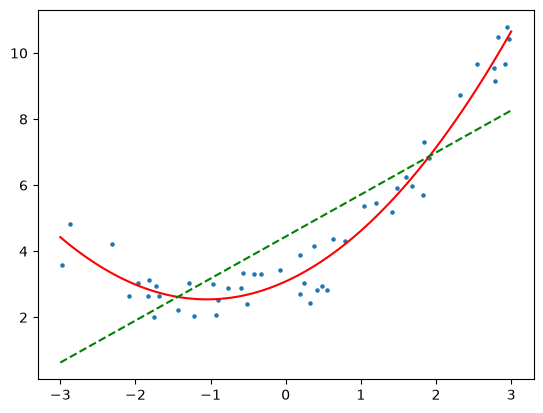

In [27]:
def func(x):
    return polyMd.coef_[0, 1]*x**2 + polyMd.coef_[0, 0]*x + polyMd.intercept_[0]

plt.scatter(X, y, s = 5)

xx = np.linspace(-3, 3, 100).reshape(-1, 1)
xx_poly = poly_features.transform(xx)
yy = polyMd.predict(xx_poly)

plt.plot(xx, yy, 'r-')

lrModel = LinearRegression()
lrModel.fit(X, y)
plt.plot(xx, lrModel.predict(xx), 'g--')

Automatically created module for IPython interactive environment
Degree: 1, Score: -0.4077289625098685
Degree: 4, Score: -0.04320874987232012
Degree: 11, Score: -0.21884058614082913
Degree: 18, Score: -1.3697359675680358


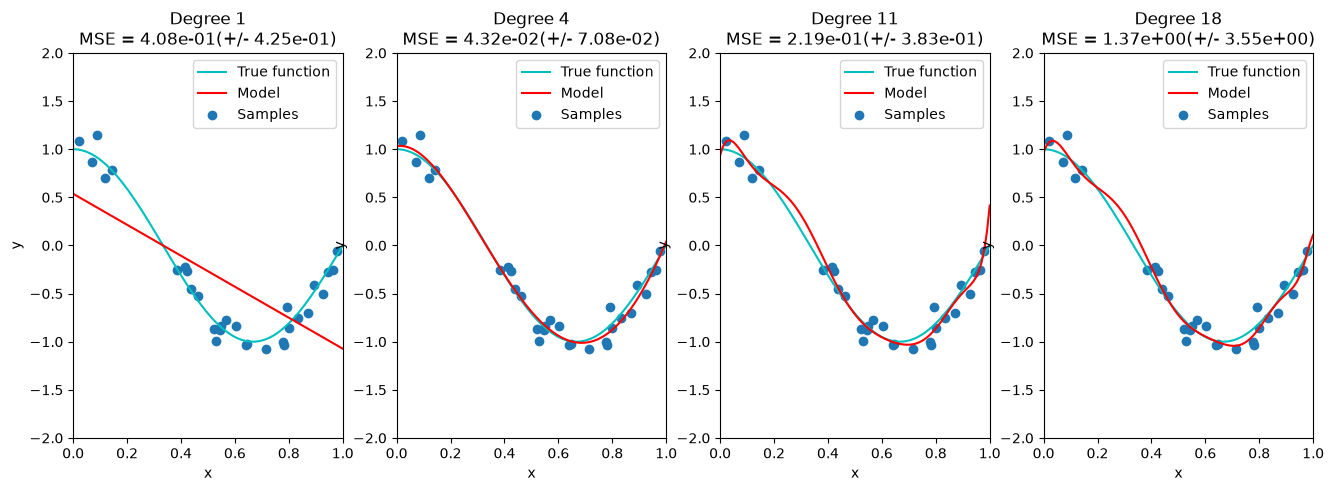

In [30]:
## Overfitting/Underfitting

print(__doc__)

import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

np.random.seed(0)

n_samples = 30
degrees = [1, 4, 11, 18]
true_fun = lambda X: np.cos(1.5 * np.pi * X)
X = np.sort(np.random.rand(n_samples))
y = true_fun(X) + np.random.randn(n_samples) * 0.1

plt.figure(figsize = (16, 5))
for i in range(len(degrees)):
    plt.subplot(1, len(degrees), i + 1)
    # ax = plt.subplot(1, len(degrees), i + 1)
    # plt.setp(ax, xticks = (), yticks = ())

    polynomial_features = PolynomialFeatures(degree = degrees[i],
                                             include_bias = False)
    lrMd = LinearRegression()
    pipeline = Pipeline([("polynomial_features", polynomial_features),
                         ("linear_regression", lrMd)])
    pipeline.fit(X[:, np.newaxis], y)

    # Evaluate the models using crossvalidation
    scores = cross_val_score(pipeline, X[:, np.newaxis], y,
                             scoring = 'neg_mean_squared_error', cv = 10)
    print("Degree: {}, Score: {}".format(degrees[i], scores.mean()))

    X_test = np.linspace(0, 1, 100)

    plt.plot(X_test, true_fun(X_test), label = "True function", c = "c")
    plt.plot(X_test, pipeline.predict(X_test[:, np.newaxis]), label = "Model", c = "r")
    plt.scatter(X, y, label = 'Samples')
    plt.xlabel("x")
    plt.ylabel("y")
    plt.xlim((0, 1))
    plt.ylim((-2, 2))
    plt.legend(loc = "best")
    plt.title("Degree {}\nMSE = {:.2e}(+/- {:.2e})".format(degrees[i], -scores.mean(), scores.std()))

plt.show()

# Logistic Regression

In [9]:
import numpy as np
from sklearn.linear_model import LogisticRegression

logiMd = LogisticRegression(C = 0.2)
y_data = np.array([0, 1])

x_data = np.array([[2, 4],
                   [4, 11],
                     [6, 6],
                     [8, 5],
                     [10, 7],
                     [12, 16],
                     [14, 8],
                     [16, 3],
                     [18, 7]])

t_data = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1])

logiMd.fit(x_data, t_data)
print(logiMd.get_params())

{'C': 0.2, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 0.0, 'max_iter': 100, 'n_jobs': None, 'penalty': 'deprecated', 'random_state': None, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}


In [11]:
print("학습 데이터 점수 : ", logiMd.score(x_data, t_data))

학습 데이터 점수 :  1.0


In [13]:
test_data = np.array([[3, 5],
                      [5, 10],
                      [7, 8],
                      [9, 12],
                      [11, 14]])
pred = logiMd.predict(test_data)

print(pred)

[0 0 0 1 1]


In [14]:
print(logiMd.coef_) # 기울기
print(logiMd.intercept_) # 절편

[[0.52657208 0.14541484]]
[-5.82025077]


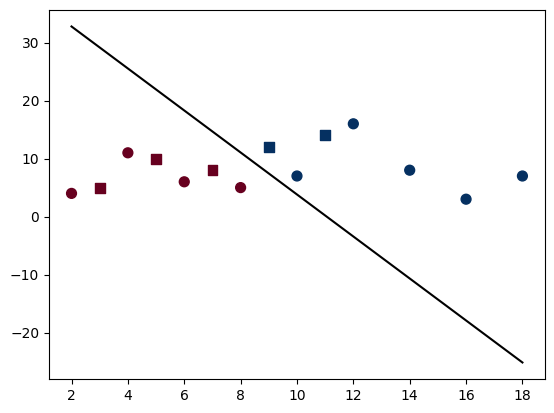

In [17]:
import matplotlib.pyplot as plt

plt.scatter(x_data[:, 0], x_data[:, 1], c = t_data, s = 50, cmap = 'RdBu')
plt.plot(x_data[:, 0], (-logiMd.intercept_ - logiMd.coef_[0][0]*x_data[:, 0])/logiMd.coef_[0][1], 'k-')
plt.scatter(test_data[:, 0], test_data[:, 1], c = pred, s = 50, cmap = 'RdBu', marker = 's')

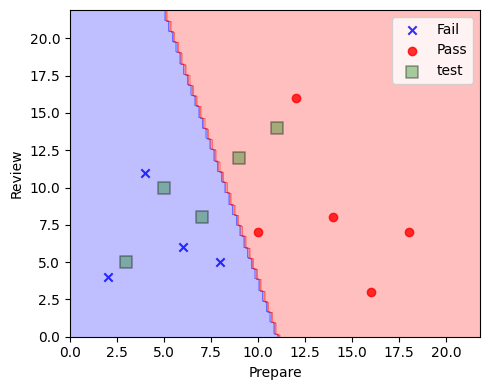

In [18]:
from matplotlib.colors import ListedColormap

x1min, x1max = 0, 22
x2min, x2max = 0, 22
xx1, xx2 = np.meshgrid(np.arange(x1min, x1max, 0.2),
                       np.arange(x2min, x2max, 0.1))

Z = logiMd.predict(np.array([xx1.ravel(), xx2.ravel()]).T)
Z = Z.reshape(xx1.shape)

failpass = ("Fail", "Pass")
markers = ('x', 'o')
colors = ('blue', 'red')
cmap = ListedColormap(colors)

plt.figure(figsize = (5, 4))
plt.contourf(xx1, xx2, Z, alpha = 0.25, cmap = cmap)
plt.xlim(xx1.min(), xx1.max())
plt.ylim(xx2.min(), xx2.max())

failpass = ("Fail", "Pass")
markers = ('x', 'o')
colors = ('blue', 'red')
cmap = ListedColormap(colors)

for idx, cl in enumerate(np.unique(t_data)):
    plt.scatter(x = x_data[t_data == cl, 0],
                y = x_data[t_data == cl, 1],
                alpha = 0.8, c = colors[idx],
                marker = markers[idx], label = failpass[cl])
    
plt.scatter(test_data[:, 0], test_data[:, 1],
            c = 'green', edgecolor = 'k', alpha = 0.35,
            linewidth = 1.2, marker = 's', s = 80, label = 'test')

plt.xlabel('Prepare')
plt.ylabel('Review')
plt.legend(loc = 'upper right')
plt.tight_layout()
plt.show()

In [19]:
x = np.array([1, 2, 3, 4])
y = np.array([5, 6, 7])

X, Y = np.meshgrid(x, y)

print('X = \n', X)
print('Y = \n', Y)
print('X 펼침: ', X.flatten())
print('Y 펼침: ', Y.flatten())

XY_grid_data = np.stack([X.ravel(), Y.ravel()], axis = 1)

print("(x, y) 쌍 = \n", XY_grid_data)

Z = np.array([c[0] * c[1] for c in np.array([X.ravel(), Y.ravel()]).T])
print("Z = \n", Z)
Z = Z.reshape(X.shape)
print("Z shape = ", Z.shape)

X = 
 [[1 2 3 4]
 [1 2 3 4]
 [1 2 3 4]]
Y = 
 [[5 5 5 5]
 [6 6 6 6]
 [7 7 7 7]]
X 펼침:  [1 2 3 4 1 2 3 4 1 2 3 4]
Y 펼침:  [5 5 5 5 6 6 6 6 7 7 7 7]
(x, y) 쌍 = 
 [[1 5]
 [2 5]
 [3 5]
 [4 5]
 [1 6]
 [2 6]
 [3 6]
 [4 6]
 [1 7]
 [2 7]
 [3 7]
 [4 7]]
Z = 
 [ 5 10 15 20  6 12 18 24  7 14 21 28]
Z shape =  (3, 4)


# 붓꽃 데이터 분석

In [21]:
import pandas as pd
from sklearn.datasets import load_iris

iris = load_iris()

In [22]:
print(iris.data.shape)
print(iris.target.shape)


(150, 4)
(150,)


In [23]:
print(iris.keys())
print(iris.feature_names)
print(iris.target_names)
print(iris.filename)

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
['setosa' 'versicolor' 'virginica']
iris.csv


In [24]:
iris_df = pd.DataFrame(data = iris.data, columns = iris.feature_names)
iris_df['Target'] = iris.target

In [25]:
iris_df.head(5)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [27]:
iris_df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [28]:
iris_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   Target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


array([[<Axes: xlabel='sepal length (cm)', ylabel='sepal length (cm)'>,
        <Axes: xlabel='sepal width (cm)', ylabel='sepal length (cm)'>,
        <Axes: xlabel='petal length (cm)', ylabel='sepal length (cm)'>,
        <Axes: xlabel='petal width (cm)', ylabel='sepal length (cm)'>,
        <Axes: xlabel='Target', ylabel='sepal length (cm)'>],
       [<Axes: xlabel='sepal length (cm)', ylabel='sepal width (cm)'>,
        <Axes: xlabel='sepal width (cm)', ylabel='sepal width (cm)'>,
        <Axes: xlabel='petal length (cm)', ylabel='sepal width (cm)'>,
        <Axes: xlabel='petal width (cm)', ylabel='sepal width (cm)'>,
        <Axes: xlabel='Target', ylabel='sepal width (cm)'>],
       [<Axes: xlabel='sepal length (cm)', ylabel='petal length (cm)'>,
        <Axes: xlabel='sepal width (cm)', ylabel='petal length (cm)'>,
        <Axes: xlabel='petal length (cm)', ylabel='petal length (cm)'>,
        <Axes: xlabel='petal width (cm)', ylabel='petal length (cm)'>,
        <Axes: xlabel='

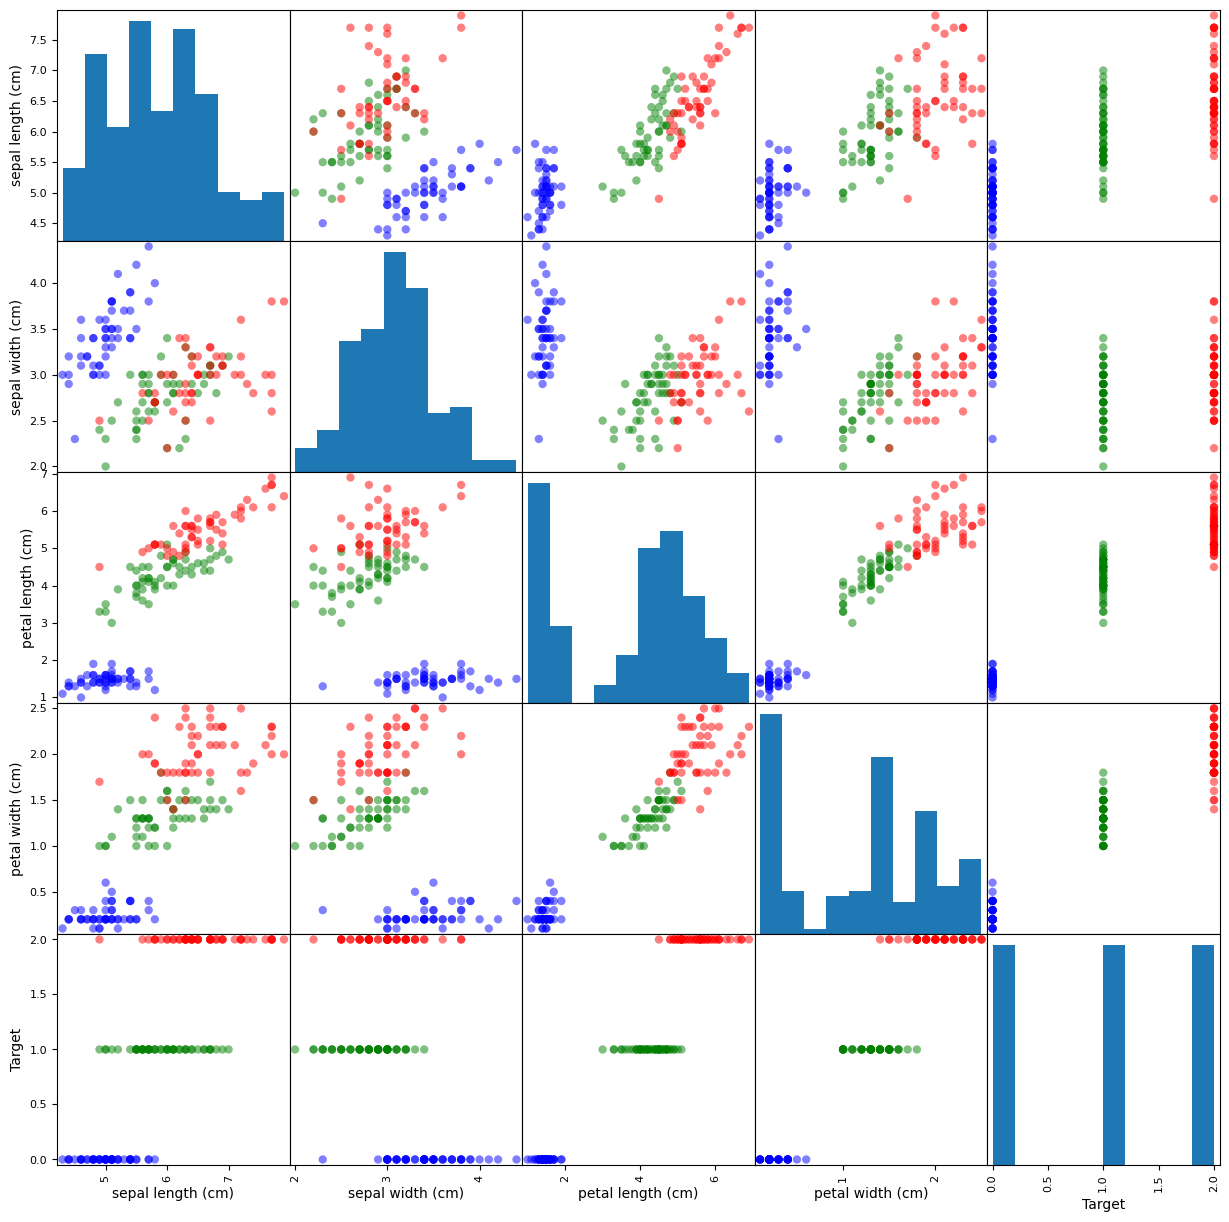

In [30]:
col_dict = {0: 'blue', 1: 'green', 2: 'red'}
cols = [col_dict[x] for x in iris_df['Target']]
pd.plotting.scatter_matrix(iris_df, color = cols, figsize = (15, 15), marker = 'o')

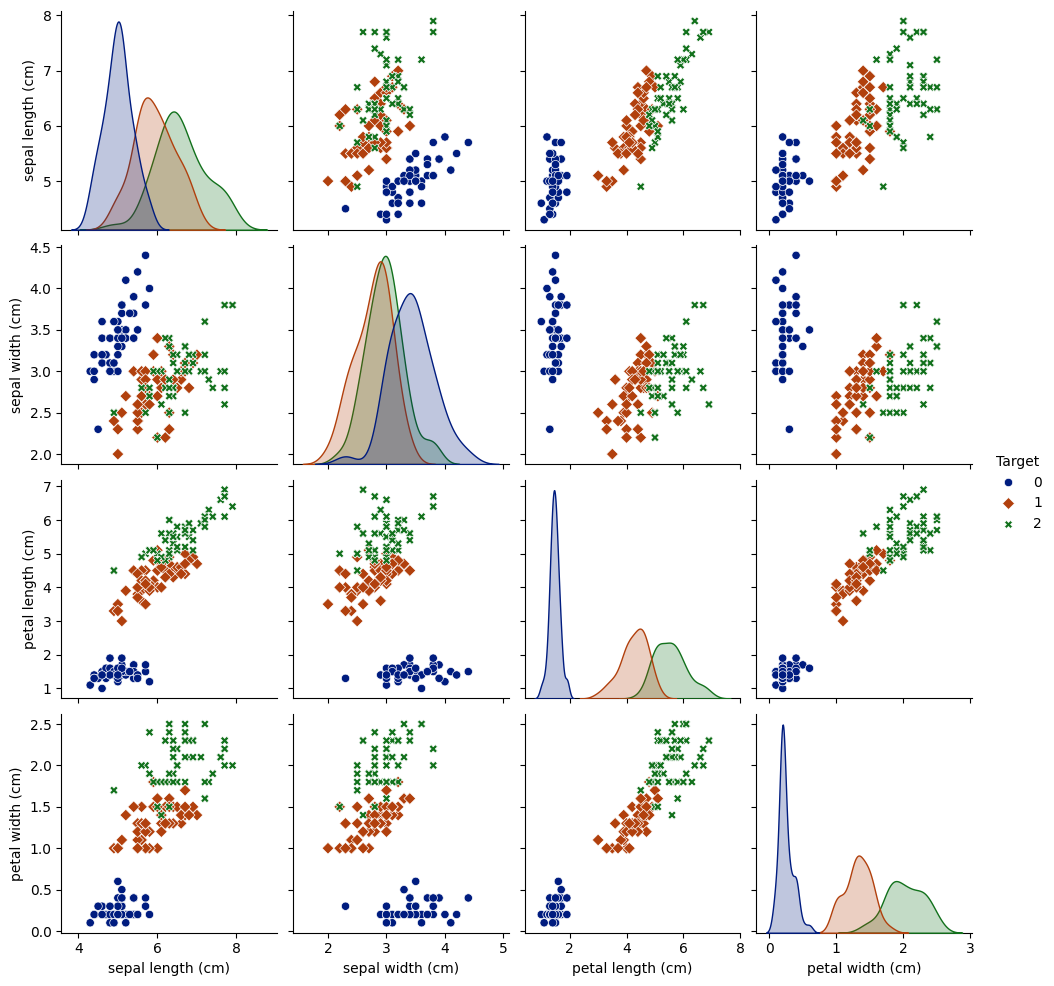

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(hue = 'Target', data = iris_df, palette = 'dark', markers = ['o', 'D', 'X'])
plt.show()

# 클러스터링
- 특별한 타겟 없이 가장 가까운 데이터 포인트를 기반으로 예측을 수행하는 방법
- 분류와 회귀 모두 지원
# KNN
- 입력 데이터 포인트와 가장 가까운 K개로 분류
- K개의 데이터 포인트 중 가장 많은 클래스가 예측 결과

In [32]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

X, y = load_iris(return_X_y = True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 11)

In [33]:
X_train.shape, X_test.shape

((120, 4), (30, 4))

In [37]:
for i in range(3, 9, 2):
    knnMd = KNeighborsClassifier(n_neighbors = i)
    knnMd.fit(X_train, y_train)
    y_pred = knnMd.predict(X_test)
    print(f"n_neighbors = {i}")
    print(y_pred, iris.target_names[y_pred])
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print("Classification Report:\n", classification_report(y_test, y_pred))
    

n_neighbors = 3
[2 2 1 1 2 0 1 0 0 1 1 1 1 2 2 0 2 1 2 2 1 0 0 1 0 0 2 1 0 1] ['virginica' 'virginica' 'versicolor' 'versicolor' 'virginica' 'setosa'
 'versicolor' 'setosa' 'setosa' 'versicolor' 'versicolor' 'versicolor'
 'versicolor' 'virginica' 'virginica' 'setosa' 'virginica' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'setosa' 'versicolor']
Confusion Matrix:
 [[ 9  0  0]
 [ 0 10  0]
 [ 0  2  9]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00         9
           1       0.83      1.00      0.91        10
           2       1.00      0.82      0.90        11

    accuracy                           0.93        30
   macro avg       0.94      0.94      0.94        30
weighted avg       0.94      0.93      0.93        30

n_neighbors = 5
[2 2 2 1 2 0 1 0 0 1 1 1 1 2 2 0 2 1 2 2 1 0 0 1 0 0 2 1 0 1] ['virginica' 'virginica' 'virgin

## 다양한 분석 보조 도구들
- 모델 평가
- 데이터 정규화
- 교차 검증
- 최적 파라미터 찾기
- 2차원 분류 이미지

In [2]:
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier
from sklearn.manifold import TSNE
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler

## 데이터 변환 - Normalization
- StandardScaler: 평균 0, 분산 1의 표준 정규 분포로 정규화
- MinMaxScaler: 0~1 사이로 정규화

In [3]:
X, y = load_iris(return_X_y = True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42
)
print(X_test[:10, :])

[[6.1 2.8 4.7 1.2]
 [5.7 3.8 1.7 0.3]
 [7.7 2.6 6.9 2.3]
 [6.  2.9 4.5 1.5]
 [6.8 2.8 4.8 1.4]
 [5.4 3.4 1.5 0.4]
 [5.6 2.9 3.6 1.3]
 [6.9 3.1 5.1 2.3]
 [6.2 2.2 4.5 1.5]
 [5.8 2.7 3.9 1.2]]


In [4]:
md = KNeighborsClassifier(n_neighbors = 5)
md.fit(X_train, y_train)

KNeighborsClassifier()

In [5]:
print('KNN 학습 데이터 점수: ', md.score(X_train, y_train))
print('KNN 테스트 데이터 점수: ', md.score(X_test, y_test))

KNN 학습 데이터 점수:  0.9666666666666667
KNN 테스트 데이터 점수:  1.0


In [8]:
scaler = StandardScaler()

x_train = scaler.fit_transform(X_train)
x_test = scaler.transform(X_test)

print(x_train[:10, :].round(2))

[[-1.47  1.2  -1.56 -1.31]
 [-0.13  2.99 -1.28 -1.05]
 [ 1.09  0.09  0.39  0.29]
 [-1.23  0.76 -1.22 -1.31]
 [-1.72  0.31 -1.39 -1.31]
 [ 0.6  -1.26  0.73  0.96]
 [ 0.72  0.31  0.44  0.42]
 [-0.74  0.98 -1.28 -1.31]
 [-0.99  1.2  -1.33 -1.31]
 [-0.74  2.32 -1.28 -1.45]]


In [10]:
import pandas as pd

iris = load_iris()
sc_df = pd.DataFrame(data = x_train, columns = iris.feature_names)
sc_df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,1.200000e+02,1.200000e+02,1.200000e+02,1.200000e+02
mean,1.754152e-15,-1.694940e-15,-2.294461e-16,-2.960595e-17
std,1.004193e+00,1.004193e+00,1.004193e+00,1.004193e+00
min,-1.839628e+00,-2.373778e+00,-1.562535e+00,-1.446088e+00
25%,-8.644522e-01,-5.850598e-01,-1.276006e+00,-1.179118e+00
50%,-7.212234e-02,-1.378803e-01,2.998997e-01,1.557325e-01
75%,7.202076e-01,7.564785e-01,7.869979e-01,8.231577e-01
max,2.304867e+00,2.992376e+00,1.703889e+00,1.757553e+00


In [11]:
mdsc = KNeighborsClassifier()
mdsc.fit(x_train, y_train)

KNeighborsClassifier()

In [12]:
print("Normalized KNN 학습 데이터 점수: ", mdsc.score(x_train, y_train))
print("Normalized KNN 테스트 데이터 점수: ", mdsc.score(x_test, y_test))

Normalized KNN 학습 데이터 점수:  0.9583333333333334
Normalized KNN 테스트 데이터 점수:  1.0


## Cross Validation
- 머신러닝 모델이 새 데이터에 얼마나 잘 작동하는지 평가하기 위해 데이터를 여러 조각으로 나누어 학습과 검증을 반복하는 기법
    - 특정 데이터 분할에 치우친 평가를 줄이고 과적합을 막는 데 쓰임
### 작동 방식(K-Fold cross validation)
1. 전체 학습 데이터를 K개의 fold로 나눔
2. 1개 폴드를 검증용으로 두고, 나머지 K-1개의 폴드로 모델을 학습
3. 검증용 폴드를 바꿔가며 이 과정을 K번 반복
4. K번 얻은 검증 점수의 평균을 모델의 일반화 성능으로 삼음
### 주요 기법 및 장단점
- Hold out validation: 데이터를 학습용과 검증/테스트용으로 한 번만 나눔. 빠르지만 데이터 분할 방식에 따라 결과가 달라질 수 있음
- Stratified K-fold: 분류 문제에서 클래스 비율이 불균형할 때, 각 폴드가 원본과 비슷한 클래스 비율을 갖도록 나눔
- Leave-One-Out: 데이터 1개만 검증용으로 쓰고 나머지로 학습하는 방식을 전체 개수만큼 반복
- 장점: 모든 데이터를 학습과 검증에 고루 활용할 수 있어 데이터가 적을 때 유용하고 평가 신뢰도가 높아짐
- 단점: 학습과 평가를 여러 번 반복하므로 계산 시간과 비용이 늘어남

In [13]:
import os

In [14]:
cross_validate(estimator = KNeighborsClassifier(),
               X = X, y = y, cv = 5,
               n_jobs = os.cpu_count(),
               verbose = 1, return_train_score = True)

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 out of   5 | elapsed:    3.6s remaining:    5.5s
[Parallel(n_jobs=8)]: Done   5 out of   5 | elapsed:    3.6s finished


{'fit_time': array([0.01766872, 0.02037382, 0.01892447, 0.0197649 , 0.02086329]),
 'score_time': array([0.00179124, 0.00179124, 0.00178599, 0.00180602, 0.00224614]),
 'test_score': array([0.96666667, 1.        , 0.93333333, 0.96666667, 1.        ]),
 'train_score': array([0.96666667, 0.96666667, 0.975     , 0.975     , 0.96666667])}

## GridSearchCV
- 지정한 하이퍼파라미터 후보의 모든 조합을 교차검증으로 평가해 최적의 파라미터를 찾는 클래스
### 주요 파라미터와 속성
- `estimator`: 튜닝할 모델 또는 파이프라인
- `param_grid`: `{파라미터명: [후보값 리스트]}`형태의 딕셔너리
- `cv`: 교차 검증 분할 수
- `scoring`: 평가 지표: (예: `'accuracy', 'f1', 'neg_mean_squared_error'`)
- n_jobs: 병렬 처리 코어 수 (`-1`이면 전체 코어 사용)
- refit: 최적 파라미터를 찾은 뒤 전체 학습 데이터로 재학습할지 여부
### 주요 속성 (fit 이후)
- `best_params_`: 최고 점수를 낸 하이퍼파라미터 조합
- `best_score_`: 교차 검증 기준 최고 평균 점수
- `best_estimator_`: 최적 파라미터로 학습된 모델 객체(`refit = True`일 때)
- `cv_results`: 조합별 상세 점수 및 실행 시간 기록
### 장단점
- 장점: 지정한 범위 내 모든 조합을 체계적으로 탐색해 재현성이 높음
- 단점: 파라미터 개수와 후보가 늘어나면 학습 회수(조합 수 * cv)가 급증해 시간이 오래 걸릴 수 있음. 탐색 공간이 넓으면 `RandomizedSearchCV`가 더 효율적

In [15]:
param_grid = {'n_neighbors': [3, 5, 7],
              'weights': ['uniform', 'distance'],
              'algorithm': ['ball_tree', 'kd_tree', 'brute']}
gs = GridSearchCV(estimator = KNeighborsClassifier(),
                  param_grid = param_grid,
                  n_jobs = -1,
                  scoring = 'accuracy',
                  cv = 5)

gs.fit(X, y)

GridSearchCV(cv=5, estimator=KNeighborsClassifier(), n_jobs=-1,
             param_grid={'algorithm': ['ball_tree', 'kd_tree', 'brute'],
                         'n_neighbors': [3, 5, 7],
                         'weights': ['uniform', 'distance']},
             scoring='accuracy')

In [18]:
print(gs.best_params_)
print(gs.best_score_)

{'algorithm': 'ball_tree', 'n_neighbors': 7, 'weights': 'uniform'}
0.9800000000000001


In [19]:
gs.best_estimator_

KNeighborsClassifier(algorithm='ball_tree', n_neighbors=7)

## 2차원 분류 분석 이미지
### meshgrid, contour, contourf: 2차원 영역 그리기
- `np.meshgrid`: 격자 좌표 생성 
    - 역할: X축과 Y축의 1차원 범위 배열을 입력받아, 2차원 평면 전체를 덮는 바둑판 모양의 자표 행렬을 생성
    - 이유: 평면 위의 모든 미세한 점에 대해 모델의 예측값을 계산하기 위함
- `plt.contourf`: 등고선 내부 색칠(영역 표현)
    - 역할: meshgrid로 만든 좌표와 각 좌표에서의 예측 클래스 값을 바탕으로, 같은 클래스 영역을 동일한 색상으로 채움
    - 특징: 'f'는 filled를 의미하며, 분류 모델의 Decision Region을 직관적으로 보여줌(보통 alpha 값을 낮춰 투명하게 배경으로 깔아줌)
- `plt.contour()`: 등고선 테두리 그리기
    - 역할: 색이 채워진 영역 사이의 경계선을 실선이나 점선으로 명확하게 그려줌
    - 특징: contourf 위에 덧그려 클래스가 나뉘는 지점을 뚜렷하게 강조할 때 사용
### t-SNE
실제 데이터는 피쳐가 고차원인 경우가 많아 2차원 평면에 바로 그릴 수 없음
- Distributed Stochastic Neighbor Embedding, 고차원 공간에 있는 데이터 간의 유사도를 보존하면서 2차원이나 3차원으로 축소하는 비선형 차원 축소 알고리즘
- 작동 원리:
    1. 고차원 공간에서 점들 간의 거리를 정규 분포(가우시안 분포)를 이용해 확률적 유사도로 변환 
    2. 저차원 공간에서는 꼬리가 두꺼운 t-분포를 이용해 유사도를 계산
    3. 두 확률 분포 차이가 최소화되도록 저차원 좌표를 반복 학습
- 주요 특징 및 주의점
    - 지역적 구조 보존: 가까운 데이터는 2차원에서도 가깝게 군집을 잘 형성하므로 데이터 시각화에 탁월함
    - 거리 해석 주의: 군집 간의 떨어진 거리나 군집의 크기는 실제 고차원 거리와 비례하지 않을 수 있음
    - 하이퍼 파라미터: `perplexity`(이웃의 수를 결정하는 값, 5~50) 설정에 따라 결과가 달라짐

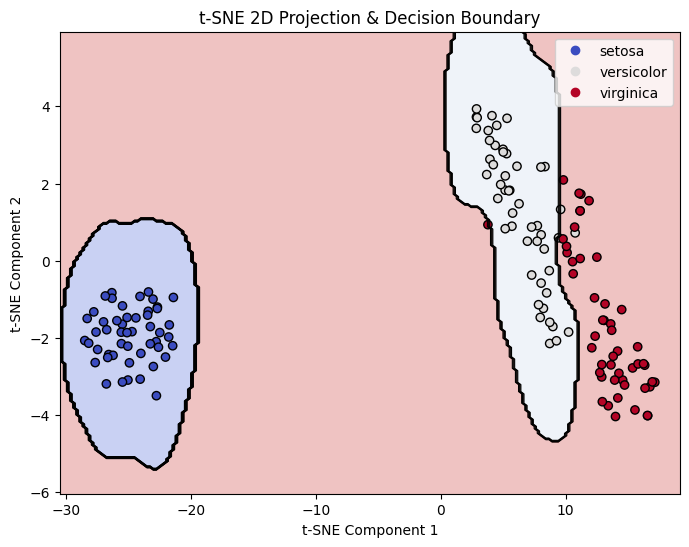

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.manifold import TSNE
from sklearn.svm import SVC

# 1. 데이터 로드 및 t-SNE를 이용한 2차원 축소
iris = load_iris()
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_2d = tsne.fit_transform(iris.data)
y = iris.target

# 2. 축소된 2차원 데이터로 분류 모델 학습
clf = SVC(kernel='rbf', gamma='auto')
clf.fit(X_2d, y)

# 3. meshgrid로 2차원 평면 격자 생성
x_min, x_max = X_2d[:, 0].min() - 2, X_2d[:, 0].max() + 2
y_min, y_max = X_2d[:, 1].min() - 2, X_2d[:, 1].max() + 2
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

# 4. 격자 내 모든 점에 대한 예측 수행
Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# 5. contourf(영역)와 contour(경계선)로 시각화
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)  # 배경 영역 색칠
plt.contour(xx, yy, Z, colors='k', linewidths=0.8)        # 결정 경계선 그리기

# 실제 데이터 산점도 표시
scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors='k')
plt.title("t-SNE 2D Projection & Decision Boundary")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.legend(handles=scatter.legend_elements()[0], labels=list(iris.target_names))
plt.show()


In [21]:
def make_mg(x, y, h = 0.1):
    x_min, x_max = x.min() - 1, x.max() + 1
    y_min, y_max = y.min() - 1, y.max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h)
                         )
    return xx, yy

def plot_cnts(clf, xx, yy, **params):
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    out = plt.contourf(xx, yy, Z, **params)
    return out

In [22]:
tsne = TSNE(n_components = 2)
Xc = tsne.fit_transform(X)
iris_2c_df = pd.DataFrame(data = Xc)
iris_2c_df['Target'] = y
display(iris_2c_df.head(5))

,0,1,Target
0,-25.502390,-1.643927,0
1,-23.042055,-0.994582,0
2,-22.787239,-2.096912,0
3,-22.498199,-1.861895,0
4,-25.574633,-2.148222,0


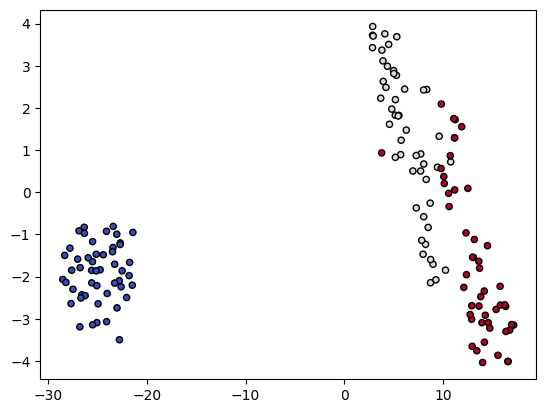

In [24]:
plt.scatter(Xc[:, 0], Xc[:, 1], c = y, cmap = plt.cm.coolwarm, s = 20, edgecolors = 'k')

In [25]:
md = KNeighborsClassifier()
md.fit(Xc, y)
pred = md.predict(Xc)

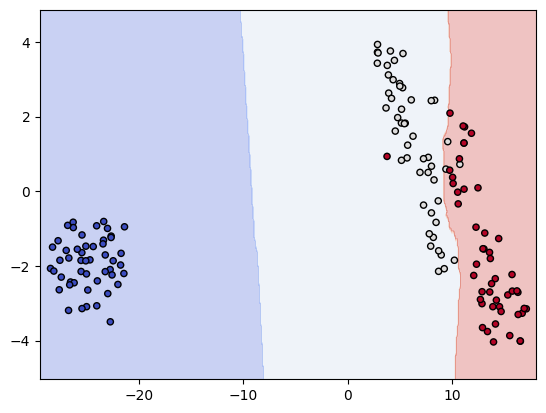

In [27]:
xx, yy = make_mg(Xc[:, 0], Xc[:, 1])
plot_cnts(md, xx, yy, cmap = plt.cm.coolwarm, alpha = 0.3)
plt.scatter(Xc[:, 0], Xc[:, 1], c = y, cmap = plt.cm.coolwarm, s = 20, edgecolors = 'k')

# SVM
Sumpport Vector Machine

데이터 클래스 간 여백(margin)을 최대화하는 최적의 결정 경계를 찾는 지도학습 머신러닝 알고리즘

- 핵심 개념
    - 초평면: 데이터를 두 클래스로 나누는 결정 경계. p차원 공간에서는 (p-1) 차원 형태로 나타남
    - 서포트 벡터: 결정 경계에 가장 가까이 위치한 데이터 포인트들로, 경계와 마진을 결정하는 핵심 기준
    - 마진: 결정 경계와 서포트 벡터 사이의 거리. 마진이 넓을수록 새로운 데이터에 대한 일반화 성능이 높아짐
- 주요 유형과 파라미터
    - 하드 마진 vs 소프트 마진: 오분류를 허용하지 않으면 하드 마진, 일부 오차나 이상치를 허용해 과적합을 줄이려면 소프트 마진을 사용. 규제 강도는 파라미터 `C`로 조절
    - Kernel Trick: 선형으로 나눌 수 없는 데이터를 고차원 공간으로 매핑해 비선형 경계를 찾음. 대표적으로 Linear, Poly, RBF, Sigmoid 커널
    - 서포트 벡터 회귀: 연속형 값을 예측하는 회귀 문제에 SVM 원리를 적용한 방식
- 장점
    - 고차원 데이터(텍스트, 생물정보학, 이미지)등에서 좋은 성능
    - 마진 극대화를 통해 과적합 방지에 유리
- 단점
    - 데이터 크기가 매우 크면 학습 시간과 메모리 비용이 커짐
    - 특성 스케일(정규화/표준화)에 민감함

In [28]:
from sklearn.svm import SVC, LinearSVC
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler

X, y = load_iris(return_X_y = True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 11)

svcMd = SVC(kernel = 'linear')
svcMd.fit(X_train, y_train)

SVC(kernel='linear')

In [29]:
print('svc 학습데이터 점수: ', svcMd.score(X_train, y_train))
print('svc 테스트데이터 점수: ', svcMd.score(X_test, y_test))

svc 학습데이터 점수:  0.9833333333333333
svc 테스트데이터 점수:  1.0


In [ ]:
scaler = StandardScaler()

scaler.fit(X_train)
x_train = scaler.transform(X_train)
x_test = scaler.transform(X_test)

In [30]:
scaledSVC = SVC(kernel = 'poly', degree = 10, coef0 = 1, C = 1)
scaledSVC.fit(x_train, y_train)

print('scaled svc 학습데이터 점수: ', scaledSVC.score(x_train, y_train))
print('scaled svc 테스트데이터 점수: ', scaledSVC.score(x_test, y_test))

scaled svc 학습데이터 점수:  0.8666666666666667
scaled svc 테스트데이터 점수:  0.36666666666666664


In [31]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import warnings
warnings.simplefilter(action = 'ignore', category = FutureWarning)

In [32]:
def make_mg(x, y, h = 0.1):
    x_min, x_max = x.min() - 1, x.max() + 1
    y_min, y_max = y.min() - 1, y.max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h)
                         )
    return xx, yy

def plot_cnts(clf, xx, yy, **params):
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    out = plt.contourf(xx, yy, Z, **params)
    return out

Xc = TSNE(n_components = 2, random_state = 2).fit_transform(X);
X0, X1 = Xc[:, 0], Xc[:, 1]
xx, yy = make_mg(X0, X1)

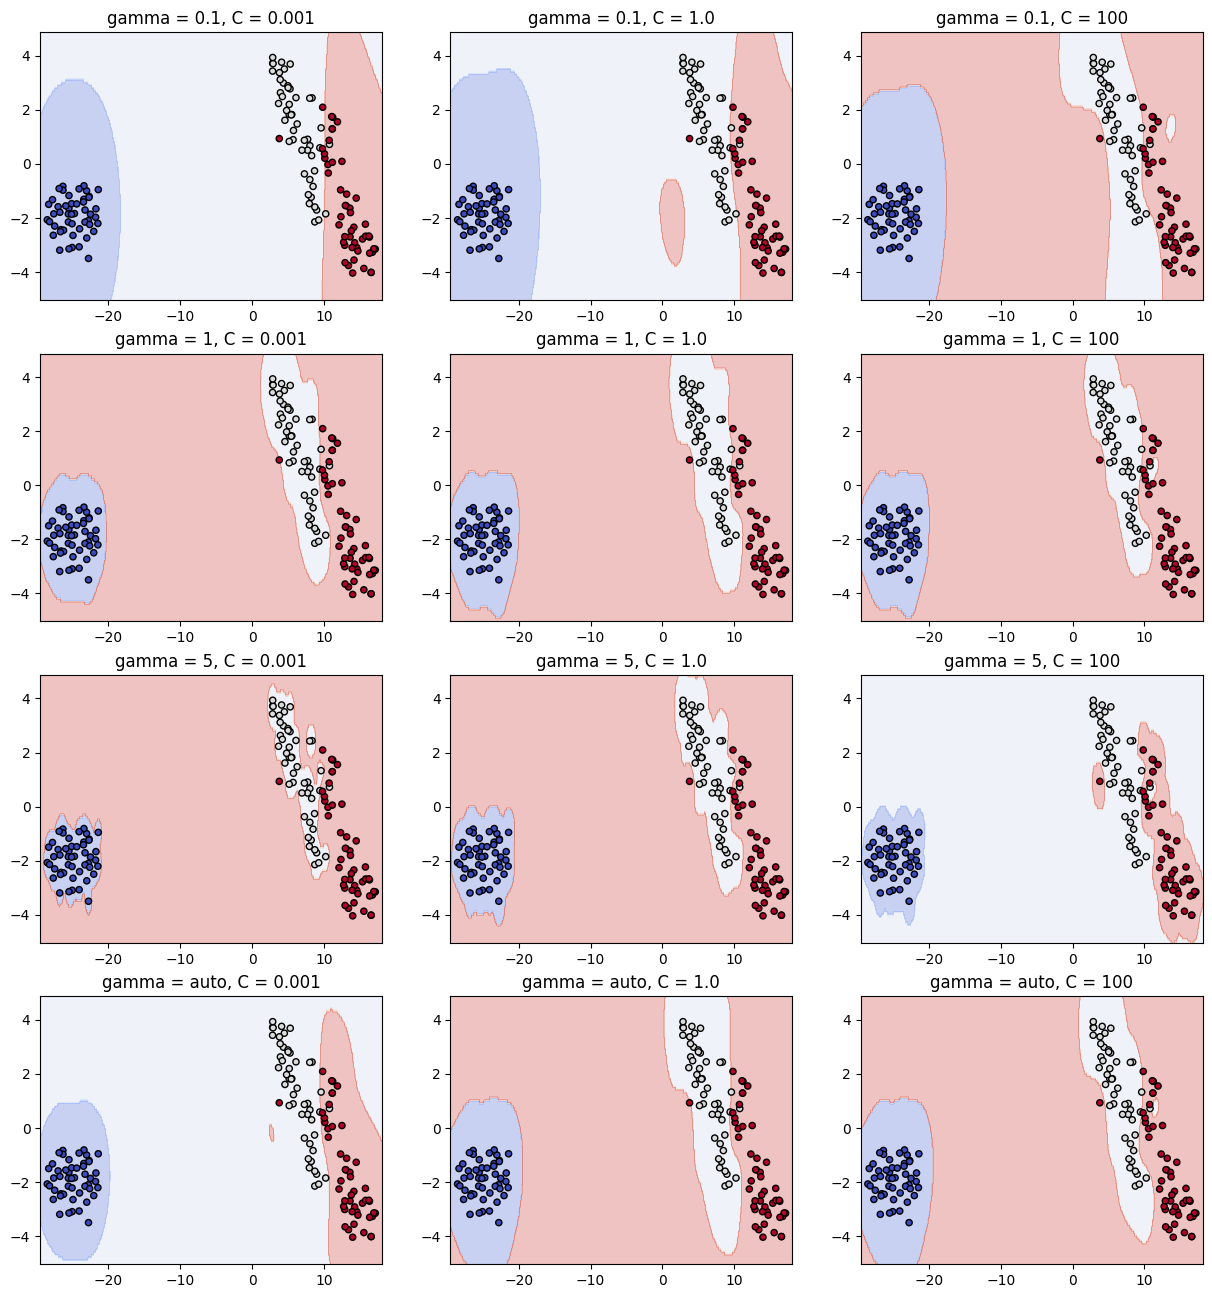

In [33]:
gamma = [0.1, 1, 5, 'auto']
C = [0.001, 1.0, 100]
row = len(gamma)
col = len(C)

plt.figure(figsize = (5*col, 4*row))

i = 1

for g in gamma:
    for c in C:
        plt.subplot(row, col, i)
        testSVC = SVC(kernel = 'rbf', C = c, gamma = g)
        testSVC.fit(Xc, y)
        plot_cnts(testSVC, xx, yy, cmap = plt.cm.coolwarm, alpha = 0.3)
        plt.scatter(X0, X1, c = y, cmap = plt.cm.coolwarm, s = 20, edgecolors = 'k')
        plt.title("gamma = {}, C = {}".format(g, c))
        i += 1

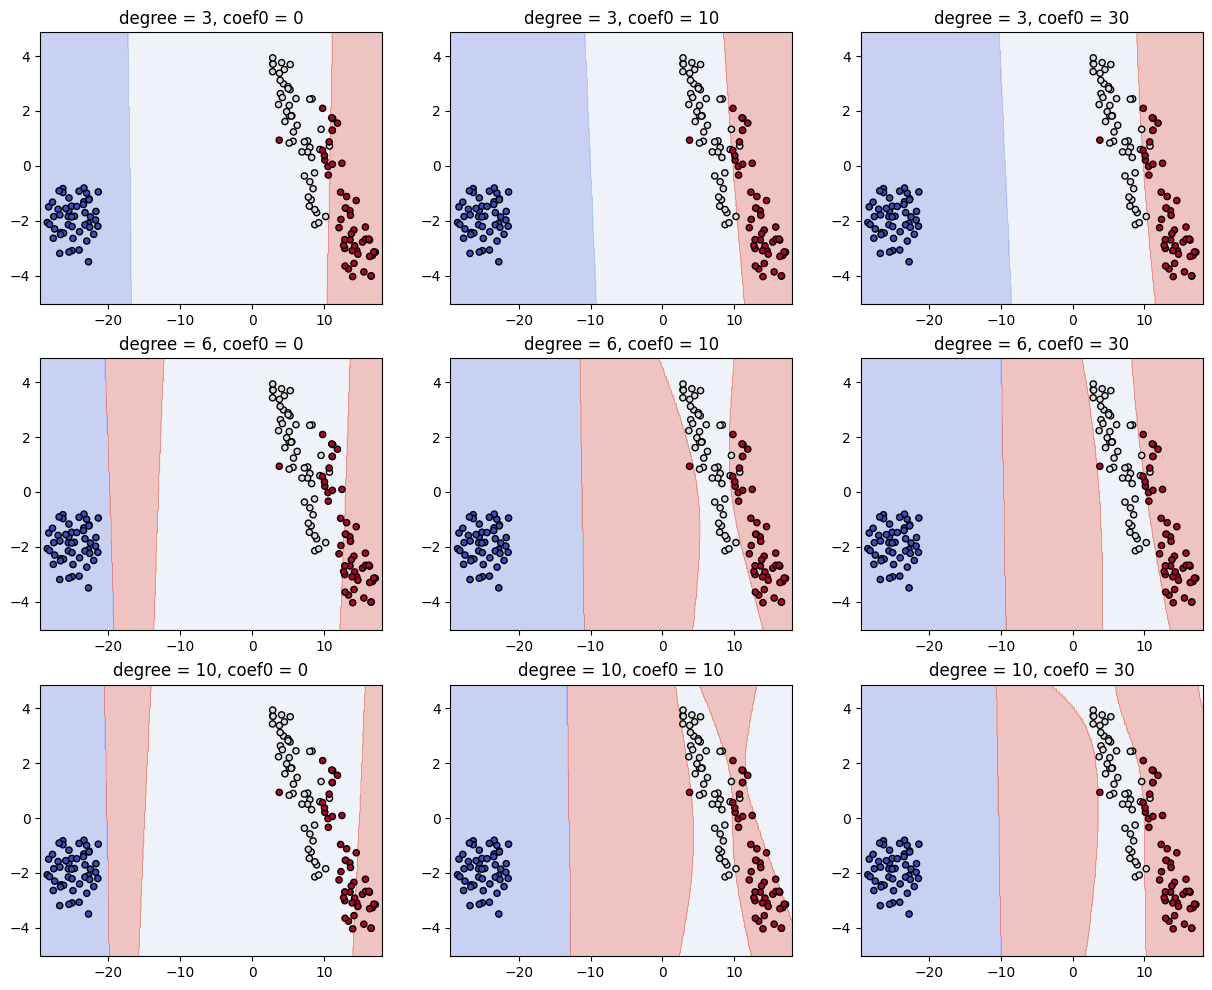

In [34]:
degree = [3, 6, 10]
coef0 = [0, 10, 30]
reg = 1
row = len(degree)
col = len(coef0)

plt.figure(figsize = (5*col, 4*row))
i = 1
for d in degree:
    for c in coef0:
        plt.subplot(row, col, i)
        testSVC = SVC(kernel = 'poly', degree = d, coef0 = c, C = reg)
        testSVC.fit(Xc, y)
        plot_cnts(testSVC, xx, yy, cmap = plt.cm.coolwarm, alpha = 0.3)
        plt.scatter(X0, X1, c = y, cmap = plt.cm.coolwarm, s = 20, edgecolors = 'k')
        plt.title("degree = {}, coef0 = {}".format(d, c))
        i += 1

# Decision Tree
- 분류와 회귀에 사용되는 지도 학습 방법
- 데이터 특성으로부터 추론된 결정 규칙을 통해 값을 예측
- if-then-else 결정 규칙을 통해 데이터 학습
- 트리의 깊이가 깊을수록 복잡한 모델 (과대적합 가능성)
- 장점
    - 이해와 해석이 쉬움
    - 시각화가 용이
    - 많은 데이터 전처리가 필요하지 않음
    - 수치형과 범주형 데이터 모두를 다룰 수 있음

In [36]:
import numpy as np
%pip install graphviz -q
import graphviz

from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import cross_validate

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [37]:
iris = load_iris()
dtMd = DecisionTreeClassifier()
dtMd.fit(iris.data, iris.target)

DecisionTreeClassifier()

In [39]:
test_ex = np.array([[6, 3, 5, 1.6]])
pred = dtMd.predict(test_ex)
print(pred, iris.target_names[pred[0]])

[1] versicolor


In [41]:
dt = tree.export_text(decision_tree = dtMd,
                      feature_names = iris.feature_names)
print(dt)

|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.75
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- petal width (cm) <= 1.65
|   |   |   |   |--- class: 1
|   |   |   |--- petal width (cm) >  1.65
|   |   |   |   |--- class: 2
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- petal width (cm) <= 1.55
|   |   |   |   |--- class: 2
|   |   |   |--- petal width (cm) >  1.55
|   |   |   |   |--- petal length (cm) <= 5.45
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- petal length (cm) >  5.45
|   |   |   |   |   |--- class: 2
|   |--- petal width (cm) >  1.75
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- sepal length (cm) <= 5.95
|   |   |   |   |--- class: 1
|   |   |   |--- sepal length (cm) >  5.95
|   |   |   |   |--- class: 2
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- class: 2



[Text(0.5, 0.9166666666666666, 'petal length (cm) <= 2.45\ngini = 0.667\nsamples = 150\nvalue = [50, 50, 50]\nclass = setosa'),
 Text(0.4230769230769231, 0.75, 'gini = 0.0\nsamples = 50\nvalue = [50, 0, 0]\nclass = setosa'),
 Text(0.46153846153846156, 0.8333333333333333, 'True  '),
 Text(0.5769230769230769, 0.75, 'petal width (cm) <= 1.75\ngini = 0.5\nsamples = 100\nvalue = [0, 50, 50]\nclass = versicolor'),
 Text(0.5384615384615384, 0.8333333333333333, '  False'),
 Text(0.3076923076923077, 0.5833333333333334, 'petal length (cm) <= 4.95\ngini = 0.168\nsamples = 54\nvalue = [0, 49, 5]\nclass = versicolor'),
 Text(0.15384615384615385, 0.4166666666666667, 'petal width (cm) <= 1.65\ngini = 0.041\nsamples = 48\nvalue = [0, 47, 1]\nclass = versicolor'),
 Text(0.07692307692307693, 0.25, 'gini = 0.0\nsamples = 47\nvalue = [0, 47, 0]\nclass = versicolor'),
 Text(0.23076923076923078, 0.25, 'gini = 0.0\nsamples = 1\nvalue = [0, 0, 1]\nclass = virginica'),
 Text(0.46153846153846156, 0.416666666666

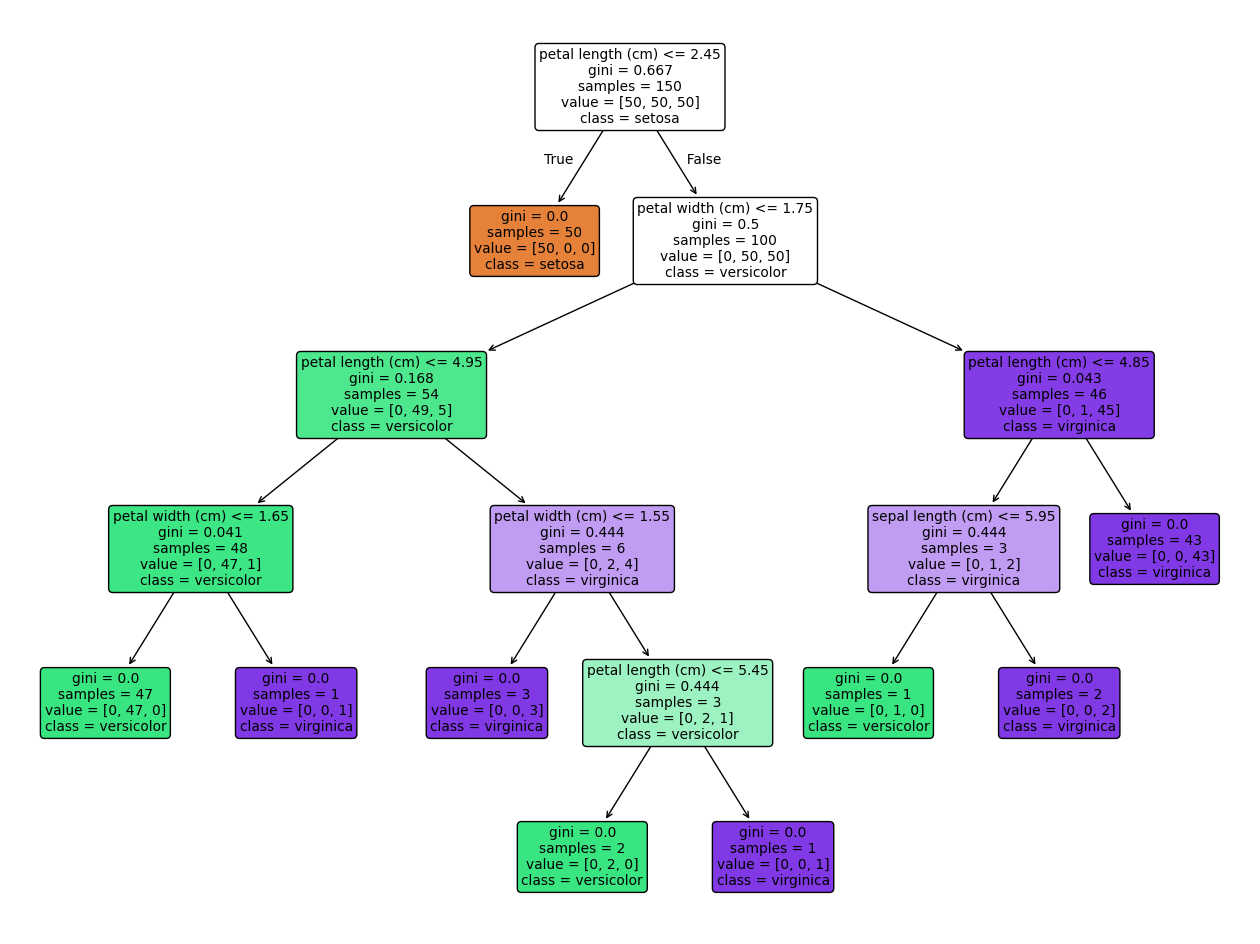

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize = (16, 12))
tree.plot_tree(dtMd, filled = True, rounded = True,
               feature_names = iris.feature_names, class_names = iris.target_names)

In [44]:
gdt = tree.export_graphviz(decision_tree = dtMd,
                           feature_names = iris.feature_names,
                           class_names = iris.target_names,
                           filled = True,
                           rounded = True,
                           special_characters = True)
graph = graphviz.Source(gdt)
graph

ExecutableNotFound: failed to execute WindowsPath('dot'), make sure the Graphviz executables are on your systems' PATH

# 사공운교수님 파트
범주형 변수는 머신러닝 전 더미변수화 필수